# Subtipos Moleculares del Cáncer de Cabeza y Cuello: PCA y Clustering (TCGA-HNSC)

**Autor:** Arturo Vargas Espinosa

# Introducción, Planteamiento del Problema y Contexto

El **carcinoma de células escamosas de cabeza y cuello** (HNSC, por sus siglas en inglés) es el cáncer que nace en el epitelio que recubre la boca, la garganta y la laringe. Bajo el mismo nombre se agrupan tumores de sitios distintos:

- **Cavidad oral:** lengua, piso de la boca, encías, paladar y mucosa de las mejillas.
- **Orofaringe:** amígdalas y base de la lengua.
- **Laringe e hipofaringe:** la laringe ("caja de la voz") y la parte baja de la garganta.

Sus dos factores de riesgo clásicos son el **tabaco** y el **alcohol**. El tercero es la infección por el **virus del papiloma humano (VPH)**, sobre todo el tipo 16, que hoy causa la mayoría de los tumores de amígdala y base de la lengua. Los tumores por VPH aparecen en pacientes más jóvenes y tienen mejor pronóstico que los causados por tabaco.

## ¿Por qué es relevante el problema?

Bajo la etiqueta de "cáncer de cabeza y cuello" hay enfermedades con biología distinta, pero en la práctica casi todas se tratan igual: cirugía, radiación y quimioterapia según la etapa. Si los tumores se separan en grupos con perfiles de expresión génica distintos, esos grupos pueden explicar por qué a unos pacientes les va mejor que a otros, y son el primer paso para diseñar tratamientos específicos para cada subtipo.

## ¿Por qué un enfoque no supervisado?

No se quiere predecir una variable conocida, sino descubrir si los tumores se organizan solos en grupos. Por eso se usa **aprendizaje no supervisado**: el PCA y el clustering se hacen **solo con la expresión génica**, sin ver ninguna variable clínica. Las variables clínicas (sitio, sexo, edad, etapa, tabaco, alcohol y supervivencia) se cruzan con los clusters **hasta el final**, para revisar si los grupos tienen sentido clínico. Si un grupo formado solo con genes concentra, por ejemplo, a los tumores de amígdala con mejor supervivencia, eso es evidencia de que el clustering encontró biología real y no ruido.

## Fuente y contexto de los datos

Los datos vienen de The Cancer Genome Atlas (TCGA), el proyecto del Instituto Nacional del Cáncer de Estados Unidos que caracterizó molecularmente miles de tumores de 33 tipos de cáncer. Se descargaron de la plataforma UCSC Xena, GDC TCGA Head and Neck Cancer (HNSC):

Tabla 1. Archivos usados

| Archivo (en Datos/) | Archivo original en Xena | Contenido |
|---|---|---|
| hnsc_expresion_star_tpm.tsv | TCGA-HNSC.star_tpm.tsv.gz | Expresión génica por RNA-seq (STAR - TPM) en escala $\log_2(\text{TPM}+1)$ |
| mapeo_genes_gencode_v36.tsv | gencode.v36.annotation.gtf.gene.probemap | ID de Ensembl de cada gen con su nombre y cromosoma |
| hnsc_fenotipo.tsv | TCGA-HNSC.clinical.tsv.gz | Variables clínicas y demográficas |
| hnsc_supervivencia.tsv | TCGA-HNSC.survival.tsv.gz | Supervivencia global: días de seguimiento y si el paciente falleció |

**TPM** (*transcripts per million*) indica cuántas copias del ARN de cada gen hay por cada millón de transcritos de la muestra. Ya viene corregido por la profundidad de secuenciación y por el largo de cada gen, así que se puede comparar entre muestras.

Con este análisis se responden tres preguntas:

1. ¿Los tumores de cabeza y cuello forman grupos naturales según su expresión génica?
2. ¿Qué genes distinguen a cada grupo y qué biología representan?
3. ¿Los grupos se relacionan con el sitio del tumor, el perfil del paciente y su supervivencia?

# Metodología

En esta sección se explica el orden del análisis y la idea detrás de cada técnica, para que los resultados se puedan leer sin revisar el código.

## Protocolo

Primero se exploran los datos para entender su tamaño, qué tipos de muestra hay, si faltan valores, cómo se distribuye la expresión y si hay muestras raras. Después se preparan: se dejan solo los tumores primarios, se quitan los genes que casi no se expresan y los de los cromosomas sexuales y mitocondriales, se eligen los 5,000 genes que más cambian entre tumores y se estandarizan.

Con esos datos se aplica PCA para resumir los 5,000 genes en unos cuantos componentes, y sobre esos componentes se hacen dos clusterings: K-means y clustering jerárquico. Se elige el número de clusters de cada uno, se comparan y se escoge un modelo final. Con ese modelo se buscan los genes que distinguen a cada cluster, y hasta ese momento se cruzan los clusters con las variables clínicas. Al final se comparan los resultados con el artículo de TCGA sobre este mismo cáncer. Todos los procesos aleatorios usan random_state=67.

### Principal Component Analysis (PCA)

PCA toma las variables originales (aquí, 5,000 genes) y las convierte en variables nuevas, llamadas componentes principales, que no están correlacionadas entre sí y que van capturando la mayor varianza posible. El primer componente es la combinación de genes

$$Z_1 = \phi_{11}X_1 + \phi_{21}X_2 + \dots + \phi_{p1}X_p$$

con la mayor varianza; el segundo se calcula igual pero perpendicular al primero, y así sucesivamente. Los pesos $\phi$ se llaman **cargas** y dicen cuánto aporta cada gen a cada componente, así que sirven para entender qué representa cada eje. La **varianza explicada (PVE)** de un componente es el porcentaje de la información total que captura.

En este reporte PCA sirve para dos cosas: ver los 520 tumores en una gráfica de 2 dimensiones y quitar ruido antes del clustering, quedándose solo con los primeros componentes. Antes de aplicarlo hay que estandarizar los genes para que todos pesen igual.

### K-means

K-means separa las observaciones en $K$ grupos buscando que los miembros de cada grupo estén lo más cerca posible de su centroide, que es el promedio del grupo:

$$\underset{C_1,\dots,C_K}{\text{minimizar}} \sum_{k=1}^{K} \sum_{i \in C_k} \lVert x_i - \mu_k \rVert^2$$

El algoritmo asigna cada tumor al centroide más cercano, recalcula los centroides y repite hasta que nadie cambia de grupo. Como el resultado depende de dónde empieza, se corre 50 veces con inicios distintos (n_init=50) y se queda con la mejor solución. Hay que decirle $K$ desde antes.

### Clustering jerárquico

El clustering jerárquico empieza con cada tumor como su propio grupo y en cada paso junta a los dos grupos más parecidos, hasta que todos quedan en uno. El resultado es un **dendrograma**, un árbol en el que entre más abajo se unen dos ramas, más parecidas son. Para obtener los clusters se corta el árbol a cierta altura, así que no hace falta fijar $K$ antes.

Para medir qué tan parecidos son dos grupos se usa un **linkage**. *Complete* usa la distancia más grande entre sus miembros, *average* usa el promedio de todas las distancias y *Ward* junta los grupos que menos aumentan la variación dentro de los clusters, que es lo mismo que busca K-means. En los tres se usa distancia euclideana, igual que en K-means, para poder comparar los métodos.

### Número de clusters

En K-means el número de clusters se elige con el **coeficiente de silueta**, que compara qué tan cerca está cada tumor de su propio cluster contra qué tan cerca está del cluster vecino. Va de -1 a 1, y entre más alto, mejor separados están los grupos. Se elige el $K$ con la silueta más alta y también se revisa el codo de la inercia (la variación dentro de los clusters). En el jerárquico se revisa el dendrograma, buscando los saltos de altura más grandes entre una unión y la siguiente.

### Análisis de genes y análisis clínico

Para saber qué genes distinguen a cada cluster se compara cada gen entre los tumores del cluster y el resto con una **prueba t de Welch**. Como son miles de pruebas a la vez, los p-values se corrigen con **Benjamini-Hochberg**; sin esa corrección saldrían cientos de genes "significativos" solo por azar. Además se mide el tamaño de la diferencia con el **log2 fold change**: un valor de 1 quiere decir que el gen se expresa el doble en ese cluster. Un gen cuenta como diferencial si tiene q < 0.05 y un log2 fold change de al menos 1, hacia arriba o hacia abajo.

Las variables clínicas se comparan entre clusters con una **prueba ji-cuadrada** para las categóricas (sitio, sexo, etapa y alcohol) y con **Kruskal-Wallis** para las numéricas (edad y paquetes-año), que no necesita que los datos sean normales. Para la supervivencia se usan curvas de **Kaplan-Meier**, que estiman la probabilidad de seguir vivo a lo largo del tiempo tomando en cuenta a los pacientes que seguían vivos al terminar su seguimiento, y la prueba **log-rank** para ver si las curvas son distintas.

# Exploración y comprensión del conjunto de datos

Empezamos importando las libreriass y leyendo los 4 archivos. La expreison viene con los genes como filas y las muestras como columnas.

In [ ]:
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from scipy.optimize import linear_sum_assignment
from scipy.cluster.hierarchy import linkage, dendrogram, fcluster, set_link_color_palette
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score, adjusted_rand_score
%matplotlib inline
warnings.filterwarnings('ignore')
sns.set_theme(style='whitegrid')

expr = pd.read_csv('Datos/hnsc_expresion_star_tpm.tsv', sep='\t', index_col=0)
mapa = pd.read_csv('Datos/mapeo_genes_gencode_v36.tsv', sep='\t', index_col=0)
fen = pd.read_csv('Datos/hnsc_fenotipo.tsv', sep='\t', index_col=0, low_memory=False)
sup = pd.read_csv('Datos/hnsc_supervivencia.tsv', sep='\t', index_col=0)

print("Expresion (genes x muestras):", expr.shape)
print("Mapeo de genes:              ", mapa.shape)
print("Fenotipo (muestras x vars):  ", fen.shape)
print("Supervivencia:               ", sup.shape)
expr.iloc[:5, :5]

Expresion (genes x muestras): (60660, 566)
Mapeo de genes:               (60660, 5)
Fenotipo (muestras x vars):   (604, 92)
Supervivencia:                (603, 3)


,TCGA-CR-7370-01A,TCGA-CR-6484-01A,TCGA-CR-6478-01A,TCGA-CV-A45Y-01A,TCGA-UF-A719-01A
Ensembl_ID,,,,,
ENSG00000000003.15,5.924953,3.805788,3.856836,4.375116,5.844817
ENSG00000000005.6,0.000000,0.000000,0.041944,0.000000,0.000000
ENSG00000000419.13,6.153473,6.537517,6.272193,5.910872,6.178179
ENSG00000000457.14,3.452332,2.478661,2.542109,2.246682,3.170117
ENSG00000000460.17,3.919226,2.698463,3.296472,1.779806,3.438053


In [ ]:
mapa.head()

,gene,chrom,chromStart,chromEnd,strand
id,,,,,
ENSG00000223972.5,DDX11L1,chr1,11869,14409,+
ENSG00000227232.5,WASH7P,chr1,14404,29570,-
ENSG00000278267.1,MIR6859-1,chr1,17369,17436,-
ENSG00000243485.5,MIR1302-2HG,chr1,29554,31109,+
ENSG00000284332.1,MIR1302-2,chr1,30366,30503,+


In [ ]:
sup.head()

,OS.time,OS,_PATIENT
sample,,,
TCGA-CN-5369-01A,1.0,1,TCGA-CN-5369
TCGA-IQ-A61I-01A,2.0,1,TCGA-IQ-A61I
TCGA-CV-7421-01A,2.0,1,TCGA-CV-7421
TCGA-CX-7082-01A,11.0,1,TCGA-CX-7082
TCGA-HD-A4C1-01A,11.0,0,TCGA-HD-A4C1


- La **expresión** tiene **60,660 genes y 566 muestras**. Cada fila es un gen identificado por su ID de Ensembl (ENSG00000141510.17) y cada columna una muestra.
- El **mapeo** tiene los mismos 60,660 IDs con el nombre del gen (gene) y su cromosoma (chrom). Con él se pasa de ENSG00000141510.17 a TP53.
- El **fenotipo** tiene 604 muestras y 92 variables, y la **supervivencia** 603 muestras: incluyen muestras que no tienen RNA-seq.

Cada muestra tiene un código de TCGA (*barcode*) como TCGA-CR-7370-01A: CR es el hospital, 7370 el paciente y 01 el tipo de muestra.

## Diccionario de datos

Como los nombres de las columnas no se entienden solos, vamos a armar un diccionario con las variables que se usan en el reporte, su tipo y qué significa cada una.

De las 92 variables del fenotipo, la mayoría son identificadores internos del GDC, fechas de registro, anotaciones administrativas o columnas vacías (tumor_grade y progression_or_recurrence dicen "Not Reported" en todas las muestras). Solo se describen las que se usan.

Tabla 2. Diccionario de datos

| Variable | Archivo | Tipo | Descripción |
|---|---|---|---|
| Expresión de cada gen | Expresión | Cuantitativa | $\log_2(\text{TPM}+1)$; 0 = el gen no se detectó |
| gene | Mapeo | Texto | Nombre (símbolo) del gen |
| chrom | Mapeo | Cualitativa | Cromosoma del gen: chr1 a chr22, chrX, chrY, chrM (mitocondrial) |
| Posiciones 14-15 del barcode | Expresión | Cualitativa | Tipo de muestra: 01 = tumor primario, 06 = metástasis, 11 = tejido normal |
| tissue_or_organ_of_origin.diagnoses | Fenotipo | Cualitativa | Sitio anatómico del tumor (24 categorías) |
| gender.demographic | Fenotipo | Cualitativa | Sexo: male / female |
| age_at_index.demographic | Fenotipo | Cuantitativa | Edad al diagnóstico, en años |
| ajcc_clinical_stage.diagnoses | Fenotipo | Cualitativa ordinal | Etapa clínica AJCC: Stage I a Stage IVC |
| ajcc_pathologic_stage.diagnoses | Fenotipo | Cualitativa ordinal | Etapa patológica AJCC (después de la cirugía) |
| alcohol_history.exposures | Fenotipo | Cualitativa | Consumo de alcohol: Yes / No |
| pack_years_smoked.exposures | Fenotipo | Cuantitativa | Paquetes-año: paquetes de cigarros al día × años fumando |
| OS.time | Supervivencia | Cuantitativa | Días desde el diagnóstico hasta la muerte o el último seguimiento |
| OS | Supervivencia | Cualitativa | 1 = falleció; 0 = seguía vivo en el último seguimiento (censurado) |

## Tipos de muestra

Vamos a contar cuántas muestras hay de cada tipo usando el código del barcode (posiciones 14 y 15), para saber cuántos tumores primarios tenemos y revisar si algún paciente aparece más de una vez.

In [ ]:
codigo_tipo = expr.columns.str[13:15]
nombres_tipo = {'01': 'Tumor primario', '06': 'Metastasis', '11': 'Tejido normal'}
print(pd.Series(codigo_tipo).map(nombres_tipo).value_counts())

tumores = expr.columns[codigo_tipo == '01']
print("\nPacientes unicos entre los tumores primarios:", tumores.str[:12].nunique())
print("Tumores primarios con fenotipo:", fen.index.isin(tumores).sum(),
      "| con supervivencia:", sup.index.isin(tumores).sum())

Tumor primario    520
Tejido normal      44
Metastasis          2
Name: count, dtype: int64

Pacientes unicos entre los tumores primarios: 520
Tumores primarios con fenotipo: 520 | con supervivencia: 519


De las 566 muestras, **520 son tumores primarios**, 44 son tejido normal y 2 son metástasis. Los 520 tumores son de 520 pacientes distintos (no hay pacientes repetidos), todos tienen fenotipo y 519 tienen supervivencia.

## Valores faltantes

Vamos a contar los valores vacíos en la expresión y en las variables clínicas que se van a usar (tomando "Not Reported" como vacío), para decidir qué variables sirven y qué hacer con los faltantes.

In [ ]:
print("Valores faltantes en la expresion:", expr.isna().sum().sum())

columnas_clinicas = {
    'tissue_or_organ_of_origin.diagnoses': 'Sitio del tumor',
    'gender.demographic': 'Sexo',
    'age_at_index.demographic': 'Edad',
    'ajcc_clinical_stage.diagnoses': 'Etapa clinica',
    'ajcc_pathologic_stage.diagnoses': 'Etapa patologica',
    'alcohol_history.exposures': 'Alcohol',
    'pack_years_smoked.exposures': 'Paquetes-anio',
}
fen_t = fen.reindex(tumores)[list(columnas_clinicas)].rename(columns=columnas_clinicas)
fen_t = fen_t.replace({'Not Reported': np.nan, 'not reported': np.nan})
sup_t = sup.reindex(tumores)
fen_t['Supervivencia (OS.time)'] = sup_t['OS.time']

faltantes = pd.DataFrame({'Faltantes': fen_t.isna().sum(),
                          '% faltantes': (fen_t.isna().mean() * 100).round(1)})
faltantes

Valores faltantes en la expresion: 0


,Faltantes,% faltantes
Sitio del tumor,0,0.0
Sexo,0,0.0
Edad,1,0.2
Etapa clinica,14,2.7
Etapa patologica,75,14.4
Alcohol,11,2.1
Paquetes-anio,224,43.1
Supervivencia (OS.time),1,0.2


- **La expresión no tiene ningún faltante.** Un gen que no se detectó viene como 0, no vacío.
- En la parte clínica de los 520 tumores casi no hay faltantes, con dos excepciones. **La etapa patológica falta en 14.4%** de los pacientes, contra 2.7% de la etapa clínica, así que **se usa la etapa clínica**. **Los paquetes-año faltan en 43.1%**; se usan solo con los 296 pacientes que los tienen.
- **No se agrega nada.** Las variables clínicas solo sirven para evaluar los clusters; inventarles valores sería meter información falsa justo en la evaluación. Cada prueba usa a los pacientes que tienen el dato.

## Distribuciones

Vamos a hacer un histograma con todos los valores de expresión y una curva de densidad para cada tumor, para ver cómo se reparte la expresión, cuántos ceros hay y si todos los tumores son comparables entre sí.

Valores en 0: 48.2%
Genes en 0 en los 520 tumores: 2,939
Genes con TPM >= 1 por tumor (mediana): 15,724


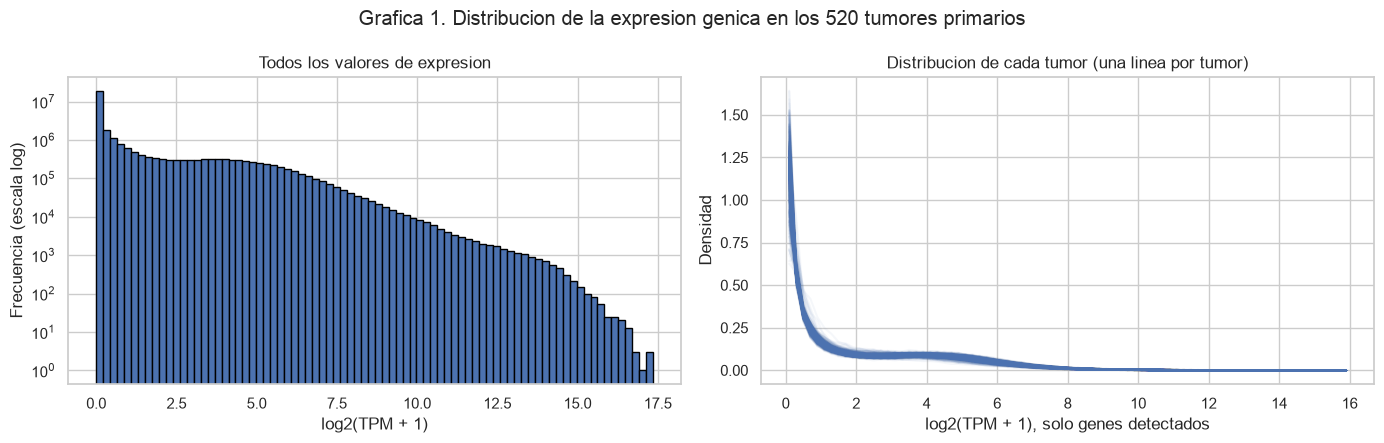

In [ ]:
 
expr_t = expr[tumores]
valores = expr_t.values.ravel()
print(f"Valores en 0: {(valores == 0).mean()*100:.1f}%")
print(f"Genes en 0 en los 520 tumores: {(expr_t.max(axis=1) == 0).sum():,}")
print(f"Genes con TPM >= 1 por tumor (mediana): {(expr_t >= 1).sum().median():,.0f}")

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
axes[0].hist(valores, bins=80, color='#4C72B0', edgecolor='black')
axes[0].set_yscale('log')
axes[0].set_xlabel('log2(TPM + 1)')
axes[0].set_ylabel('Frecuencia (escala log)')
axes[0].set_title('Todos los valores de expresion')

bins = np.linspace(0, 16, 81)
centros = (bins[:-1] + bins[1:]) / 2
for m in tumores:
    v = expr_t[m].values
    h, _ = np.histogram(v[v > 0], bins=bins, density=True)
    axes[1].plot(centros, h, color='#4C72B0', alpha=0.05)
axes[1].set_xlabel('log2(TPM + 1), solo genes detectados')
axes[1].set_ylabel('Densidad')
axes[1].set_title('Distribucion de cada tumor (una linea por tumor)')
plt.suptitle('Grafica 1. Distribucion de la expresion genica en los 520 tumores primarios')
plt.tight_layout()
plt.show()

- **48.2% de todos los valores son 0** y 2,939 genes valen 0 en los 520 tumores. La tabla incluye todos los genes anotados del genoma (también ARN no codificante y pseudogenes), y la mayoría no se expresa en este tejido. En promedio cada tumor tiene unos 15,700 genes con TPM ≥ 1.
- Entre los genes que sí se detectan hay **un pico muy alto cerca de 0**: miles de genes con apenas unas lecturas (TPM menor a 1), que son ruido de detección más que expresión real. Después viene una meseta amplia entre 2 y 7, que son los genes que de verdad están activos, y una cola de genes muy expresados que llega hasta 17 (más de 100,000 TPM).
- **Las 520 curvas de la derecha se enciman casi por completo**: todos los tumores tienen la misma distribución global, así que no hay problemas de normalización entre muestras.
- **Los datos ya vienen en escala logarítmica** ($\log_2(\text{TPM}+1)$), así que no se vuelven a transformar.

### Variables clínicas

Vamos a revisar como se reparten los pacientes por sitio del tumor, sexo, edad y etapa con gráficas de barras y un histograma, para conocer a la población antes del análisis.

El sitio viene en 24 categorías, muchas con 1 o 2 pacientes. Se agrupan en las 3 regiones anatómicas del cáncer de cabeza y cuello más una categoría para los sitios que no se pueden asignar: **cavidad oral** (lengua, piso de boca, encías, paladar, mejillas, labio), **orofaringe** (amígdala, base de lengua, pared de orofaringe), **laringe e hipofaringe** (se juntan porque solo hay 9 tumores de hipofaringe) y **sobrepuesto / sin especificar** (lesiones que abarcan varias regiones, faringe sin especificar y mandíbula). La etapa se agrupa en I-II (temprana), III y IV.

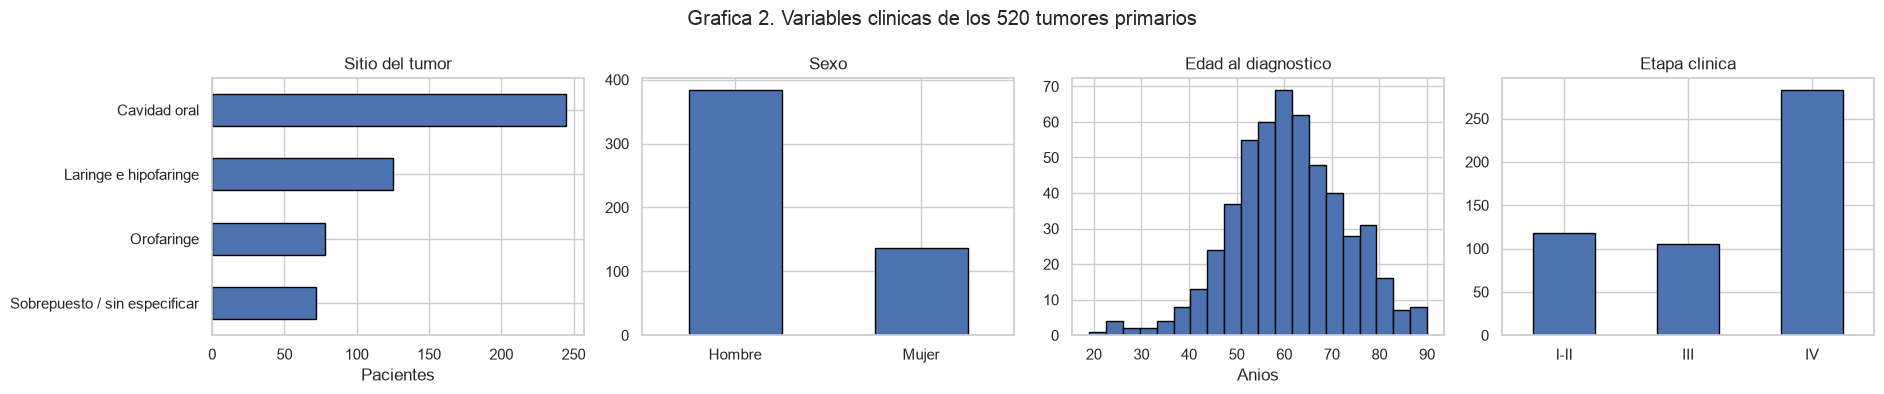

Sitio
Cavidad oral                     245
Laringe e hipofaringe            125
Orofaringe                        78
Sobrepuesto / sin especificar     72
Name: count, dtype: int64

        Edad  Paquetes-anio  Tiempo (anios)
count  519.0          296.0           519.0
mean    60.9           45.8             2.5
std     11.9           35.3             2.4
min     19.0            0.0             0.0
25%     53.0           25.0             1.0
50%     61.0           40.0             1.8
75%     68.5           60.0             3.2
max     90.0          300.0            17.6

Mujeres: 26.2% | Etapa IV: 54.4% | Fallecidos: 221 (42.6%)


In [ ]:
 
grupos_sitio = {
    'Orofaringe': ['Tonsil, NOS', 'Base of tongue, NOS', 'Oropharynx, NOS', 'Posterior wall of oropharynx'],
    'Laringe e hipofaringe': ['Larynx, NOS', 'Supraglottis', 'Hypopharynx, NOS'],
    'Sobrepuesto / sin especificar': ['Overlapping lesion of lip, oral cavity and pharynx', 'Pharynx, NOS', 'Mandible'],
}

def agrupar_sitio(s):
    if pd.isna(s):
        return np.nan
    for grupo, sitios in grupos_sitio.items():
        if s in sitios:
            return grupo
    return 'Cavidad oral'      # lengua, piso de boca, encias, paladar, mejillas, labio

def agrupar_etapa(e):
    if pd.isna(e):
        return np.nan
    if e in ['Stage I', 'Stage II']:
        return 'I-II'
    if e == 'Stage III':
        return 'III'
    return 'IV'                # IVA, IVB y IVC

clin = pd.DataFrame(index=tumores)
clin['Sitio'] = fen_t['Sitio del tumor'].map(agrupar_sitio)
clin['Sexo'] = fen_t['Sexo'].map({'male': 'Hombre', 'female': 'Mujer'})
clin['Edad'] = fen_t['Edad']
clin['Etapa'] = fen_t['Etapa clinica'].map(agrupar_etapa)
clin['Alcohol'] = fen_t['Alcohol'].map({'Yes': 'Si', 'No': 'No'})
clin['Paquetes-anio'] = fen_t['Paquetes-anio']
clin['Tiempo (anios)'] = sup_t['OS.time'] / 365.25
clin['Fallecio'] = sup_t['OS']

orden_sitio = ['Cavidad oral', 'Laringe e hipofaringe', 'Orofaringe', 'Sobrepuesto / sin especificar']
fig, axes = plt.subplots(1, 4, figsize=(19, 4))
clin['Sitio'].value_counts().reindex(orden_sitio).plot(kind='barh', ax=axes[0], color='#4C72B0', edgecolor='black')
axes[0].set_title('Sitio del tumor')
axes[0].set_xlabel('Pacientes')
axes[0].set_ylabel('')
axes[0].invert_yaxis()
clin['Sexo'].value_counts().plot(kind='bar', ax=axes[1], color='#4C72B0', edgecolor='black', rot=0)
axes[1].set_title('Sexo')
axes[1].set_xlabel('')
axes[2].hist(clin['Edad'].dropna(), bins=20, color='#4C72B0', edgecolor='black')
axes[2].set_title('Edad al diagnostico')
axes[2].set_xlabel('Anios')
clin['Etapa'].value_counts().reindex(['I-II', 'III', 'IV']).plot(kind='bar', ax=axes[3], color='#4C72B0', edgecolor='black', rot=0)
axes[3].set_title('Etapa clinica')
axes[3].set_xlabel('')
plt.suptitle('Grafica 2. Variables clinicas de los 520 tumores primarios')
plt.tight_layout()
plt.show()

print(clin['Sitio'].value_counts())
print()
print(clin[['Edad', 'Paquetes-anio', 'Tiempo (anios)']].describe().round(1))
print(f"\nMujeres: {(clin['Sexo'] == 'Mujer').mean()*100:.1f}% | Etapa IV: {(clin['Etapa'] == 'IV').mean()*100:.1f}%"
      f" | Fallecidos: {int(clin['Fallecio'].sum())} ({clin['Fallecio'].mean()*100:.1f}%)")

- **Sitio:** casi la mitad de los tumores son de cavidad oral (245), seguidos de laringe e hipofaringe (125), orofaringe (78) y sobrepuestos (72).
- **Sexo:** solo **26.2% son mujeres**, lo esperado para un cáncer ligado al tabaco y al alcohol.
- **Edad:** mediana de 61 años (de 19 a 90).
- **Etapa:** **54.4% llega en etapa IV**; la mayoría se diagnostica avanzado.
- **Supervivencia:** fallecieron 221 pacientes (42.6%). La mediana del tiempo observado (hasta la muerte o el último seguimiento) es de 1.8 años, y casi nadie pasa de 10.
- **Tabaco:** mediana de 40 paquetes-año entre los 296 pacientes con el dato.

Estas variables solo se describen aquí; no se usan hasta tener los clusters.

## Valores atípicos

Se revisan en dos niveles. **Por muestra**, se buscan tumores con una secuenciación fallida o muy distinta al resto: muy pocos genes detectados o un perfil que no se parece al tumor típico (correlación con el perfil mediano). **Por gen**, se revisan los genes con valores extremos.

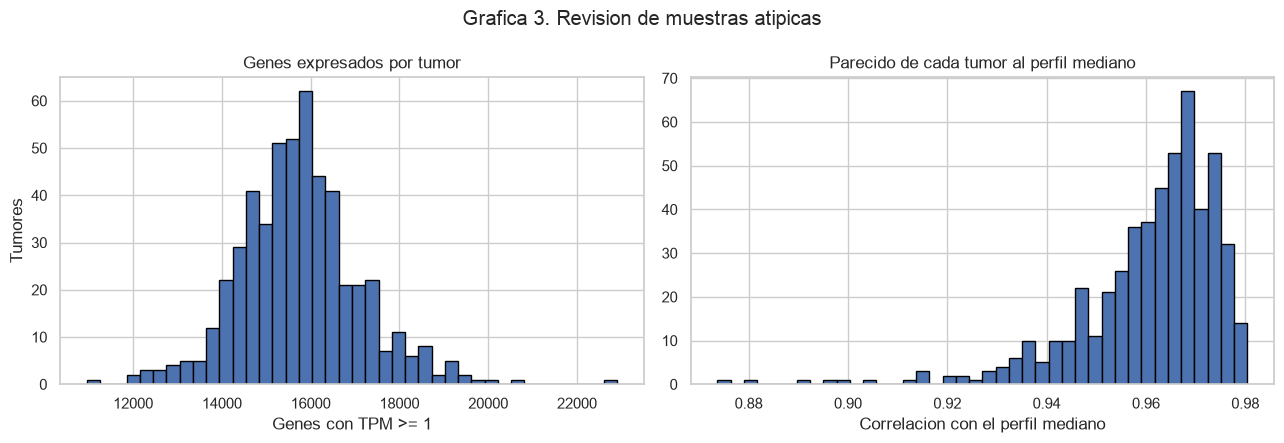

Genes expresados por tumor: min 10958 | mediana 15724 | max 22904
Tumores con |z| > 3 en genes expresados: 4

Tumores con menor correlacion con el perfil mediano:
TCGA-D6-A6EP-01A    0.874
TCGA-HD-A634-01A    0.880
TCGA-UF-A7JS-01A    0.891
TCGA-CV-A45Q-01A    0.897
TCGA-D6-A6ES-01A    0.900
dtype: float64


In [ ]:
detectados = (expr_t >= 1).sum()
corr_mediana = expr_t.corrwith(expr_t.median(axis=1))
z_detectados = (detectados - detectados.mean()) / detectados.std()

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
axes[0].hist(detectados, bins=40, color='#4C72B0', edgecolor='black')
axes[0].set_xlabel('Genes con TPM >= 1')
axes[0].set_ylabel('Tumores')
axes[0].set_title('Genes expresados por tumor')
axes[1].hist(corr_mediana, bins=40, color='#4C72B0', edgecolor='black')
axes[1].set_xlabel('Correlacion con el perfil mediano')
axes[1].set_title('Parecido de cada tumor al perfil mediano')
plt.suptitle('Grafica 3. Revision de muestras atipicas')
plt.tight_layout()
plt.show()

print("Genes expresados por tumor: min", detectados.min(), "| mediana", int(detectados.median()), "| max", detectados.max())
print("Tumores con |z| > 3 en genes expresados:", (z_detectados.abs() > 3).sum())
print("\nTumores con menor correlacion con el perfil mediano:")
print(corr_mediana.nsmallest(5).round(3))

Todos los tumores tienen entre 10,958 y 22,904 genes expresados, y **el que menos se parece al perfil mediano tiene una correlación de 0.874**; el resto está arriba de eso. Hay 4 tumores con más de 3 desviaciones estándar en genes expresados, pero todos tienen una correlación de al menos 0.87 con el perfil mediano. Ninguno tiene la firma de una muestra fallida (miles de genes perdidos o correlación baja), así que **no se elimina ningún tumor**: con 520 muestras reales, quitar tumores por ser diferentes sería quitar justo la variabilidad que se quiere estudiar.

In [ ]:
var_genes = expr_t.var(axis=1).sort_values(ascending=False)
top15 = pd.DataFrame({
    'Gen': mapa.loc[var_genes.index[:15], 'gene'].values,
    'Varianza': var_genes.iloc[:15].round(2).values,
    'Mediana': expr_t.loc[var_genes.index[:15]].median(axis=1).round(2).values,
    'Maximo': expr_t.loc[var_genes.index[:15]].max(axis=1).round(2).values,
}, index=var_genes.index[:15])
top15

,Gen,Varianza,Mediana,Maximo
Ensembl_ID,,,,
ENSG00000171345.13,KRT19,14.84,8.35,13.92
ENSG00000167768.4,KRT1,14.53,6.30,14.91
ENSG00000143632.14,ACTA1,13.87,1.83,14.50
ENSG00000175084.12,DES,13.63,2.69,13.91
ENSG00000181617.6,FDCSP,13.63,3.02,16.52
ENSG00000171401.15,KRT13,12.83,8.09,15.19
ENSG00000163209.15,SPRR3,12.80,8.08,14.32
ENSG00000170477.13,KRT4,12.55,4.87,15.03
ENSG00000159516.9,SPRR2G,11.52,7.17,13.44


Los genes más variables, con valores que van de casi 0 a más de 13 en escala log, son extremos reales y no errores. Dicen mucho de la composición de las muestras:

- **Queratinas y genes de diferenciación escamosa** (KRT19, KRT1, KRT13, KRT4, SPRR3, SPRR2G, CRNN, KRTDAP): qué tan diferenciado o queratinizado está el epitelio del tumor.
- **Genes de músculo esquelético** (ACTA1, DES, MYL1, ACTC1): algunas muestras incluyen músculo que rodeaba al tumor, sobre todo las de lengua, que es un músculo.
- **FDCSP:** se expresa en las células dendríticas foliculares del tejido linfoide, como el de las amígdalas.
- **RPS4Y1:** está en el **cromosoma Y**, así que solo se expresa en hombres. Su varianza viene del sexo del paciente, no del tumor.

Estos valores no se recortan. Son la información que va a usar el clustering, y la estandarización evita que dominen por su escala. Lo que sí cambia es el tratamiento de los genes de cromosomas sexuales, como RPS4Y1, que se decide en la preparación.

# Preparación y tratamiento de los datos

Vamos a filtrar y estandarizar la matriz de expresión para que el PCA y el clustering trabajen solo con información útil. Estas son las decisiones:

1. **Solo tumores primarios (520).** El tejido normal es mucho más distinto de cualquier tumor que los tumores entre sí; si se deja, forma su propio cluster y esconde los subtipos. Las 2 metástasis son muy pocas para formar un grupo y vienen de otro contexto biológico.
2. **No se vuelve a transformar.** Los datos ya están en $\log_2(\text{TPM}+1)$, que comprime los valores altos y acerca la distribución a una normal.
3. **Se quitan los genes poco expresados:** se conservan los genes con **TPM ≥ 1 (valor ≥ 1 en escala log) en al menos 10% de los tumores** (52 tumores). Un gen que casi nunca se detecta solo aporta ruido. El umbral de 10%, y no uno más alto, permite que sobrevivan genes exclusivos de un subgrupo chico (de 52 tumores o más).
4. **Se quitan los genes del cromosoma Y, los mitocondriales (chrM), XIST y TSIX.** Los del cromosoma Y solo se expresan en hombres, y XIST/TSIX solo en mujeres. Si se dejan, el clustering separa a los pacientes por sexo, que no es lo que se quiere estudiar, y el sexo aparecería "asociado" a los clusters por construcción. Los genes mitocondriales reflejan sobre todo la calidad de la muestra.
5. **Se usan los 5,000 genes más variables.** Un gen que vale casi lo mismo en todos los tumores no ayuda a separarlos, pero sí suma ruido a las distancias. Con 5,000 genes se cubren las vías biológicas principales y se dejan fuera los genes estables.
6. **Se estandariza cada gen (media 0, desviación estándar 1).** Así cada gen pesa lo mismo en el PCA y en las distancias, sin importar su nivel de expresión.

Para el análisis de genes de cada cluster se usan **todos los genes que pasan los pasos 3 y 4**, no solo los 5,000 más variables, en su escala $\log_2$ original.

In [ ]:
 
pasos = [('Datos originales', expr.shape[0], expr.shape[1]),
         ('1. Solo tumores primarios', expr_t.shape[0], expr_t.shape[1])]

expresado = (expr_t >= 1).mean(axis=1) >= 0.10          # TPM >= 1 en al menos 10% de los tumores
datos = expr_t[expresado]
pasos.append(('2. Genes expresados (TPM >= 1 en >= 10%)', datos.shape[0], datos.shape[1]))

cromosoma = mapa.loc[datos.index, 'chrom']
gen = mapa.loc[datos.index, 'gene']
quitar = cromosoma.isin(['chrY', 'chrM']) | gen.isin(['XIST', 'TSIX'])
print("Genes quitados -> cromosoma Y:", (cromosoma == 'chrY').sum(),
      "| mitocondriales:", (cromosoma == 'chrM').sum(),
      "| XIST y TSIX:", gen.isin(['XIST', 'TSIX']).sum())
datos = datos[~quitar.values]
pasos.append(('3. Sin genes de chrY, chrM, XIST y TSIX', datos.shape[0], datos.shape[1]))

varianza = datos.var(axis=1).sort_values(ascending=False)
n_genes = 5000
genes_top = varianza.index[:n_genes]
pasos.append((f'4. Los {n_genes:,} genes mas variables', n_genes, datos.shape[1]))

X = StandardScaler().fit_transform(datos.loc[genes_top].T)   # tumores x genes; cada gen con media 0 y desv. est. 1
pasos.append(('5. Estandarizacion (z-score por gen)', X.shape[1], X.shape[0]))

print()
print(pd.DataFrame(pasos, columns=['Paso', 'Genes', 'Tumores']).to_string(index=False))
print(f"\nVarianza del gen #{n_genes:,}: {varianza.iloc[n_genes-1]:.2f} | mediana de los genes que quedan fuera: {varianza.iloc[n_genes:].median():.2f}")
print("Media y desv. est. de los primeros 3 genes ya estandarizados:", X[:, :3].mean(axis=0).round(3), X[:, :3].std(axis=0).round(3))

Genes quitados -> cromosoma Y: 31 | mitocondriales: 28 | XIST y TSIX: 1

                                    Paso  Genes  Tumores
                        Datos originales  60660      566
               1. Solo tumores primarios  60660      520
2. Genes expresados (TPM >= 1 en >= 10%)  21008      520
 3. Sin genes de chrY, chrM, XIST y TSIX  20948      520
        4. Los 5,000 genes mas variables   5000      520
    5. Estandarizacion (z-score por gen)   5000      520

Varianza del gen #5,000: 0.82 | mediana de los genes que quedan fuera: 0.38
Media y desv. est. de los primeros 3 genes ya estandarizados: [-0.  0. -0.] [1. 1. 1.]


- El filtro de expresión deja **21,008 de 60,660 genes**. Se van casi dos terceras partes, que son genes no codificantes o que no se expresan en este tejido.
- Se quitan 31 genes del cromosoma Y, 28 mitocondriales y XIST (TSIX ya se había ido por baja expresión). Quedan **20,948 genes**, que son los que se usan en el análisis de genes.
- El gen número 5,000 tiene una varianza de 0.82, más del doble de la mediana de los genes que quedan fuera (0.38). El corte se queda con los genes que realmente cambian entre tumores.
- La matriz final X tiene **520 tumores × 5,000 genes**, con media 0 y desviación estándar 1 en cada gen.

# Reducción de dimensionalidad mediante PCA

Se ajusta PCA con todos los componentes posibles para ver cuánta varianza captura cada uno y decidir cuántos usar.

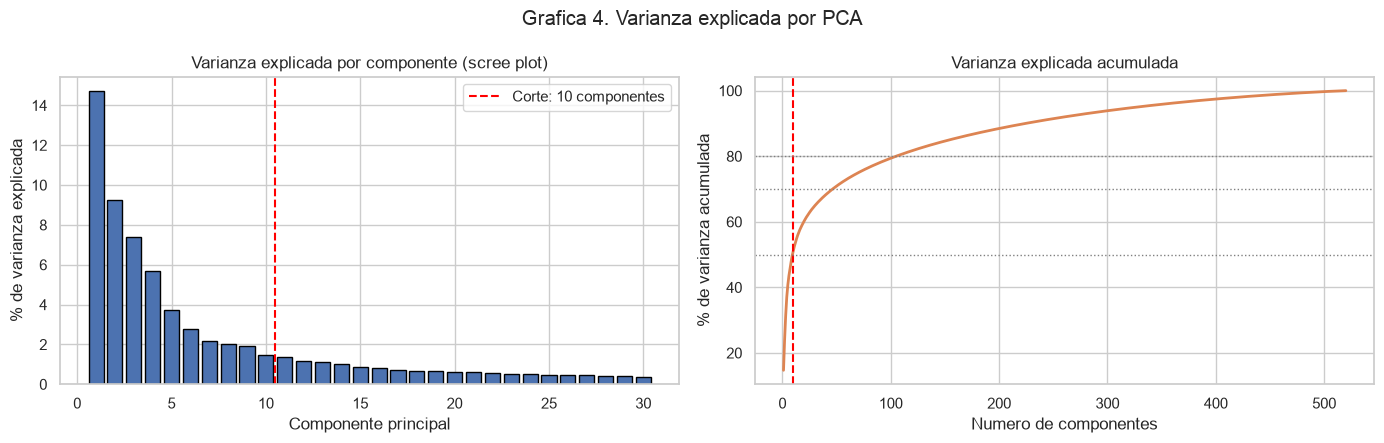

PVE de los primeros 12 componentes (%): [14.7   9.25  7.4   5.68  3.74  2.79  2.18  2.02  1.92  1.49  1.34  1.18]
Varianza acumulada con  2 componentes: 23.9%
Varianza acumulada con  5 componentes: 40.8%
Varianza acumulada con 10 componentes: 51.2%
Varianza acumulada con 20 componentes: 60.2%
Varianza acumulada con 50 componentes: 70.9%
Componentes para llegar a 50%: 10
Componentes para llegar a 70%: 47
Componentes para llegar a 80%: 105


In [ ]:
 
pca = PCA(random_state=67)
Z = pca.fit_transform(X)
pve = pca.explained_variance_ratio_
pve_acum = np.cumsum(pve)

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
n_mostrar = 30
axes[0].bar(range(1, n_mostrar + 1), pve[:n_mostrar] * 100, color='#4C72B0', edgecolor='black')
axes[0].axvline(10.5, color='red', linestyle='--', label='Corte: 10 componentes')
axes[0].set_xlabel('Componente principal')
axes[0].set_ylabel('% de varianza explicada')
axes[0].set_title('Varianza explicada por componente (scree plot)')
axes[0].legend()
axes[1].plot(range(1, len(pve_acum) + 1), pve_acum * 100, color='#DD8452', linewidth=2)
axes[1].axvline(10, color='red', linestyle='--')
for umbral in [50, 70, 80]:
    axes[1].axhline(umbral, color='gray', linestyle=':', linewidth=1)
axes[1].set_xlabel('Numero de componentes')
axes[1].set_ylabel('% de varianza acumulada')
axes[1].set_title('Varianza explicada acumulada')
plt.suptitle('Grafica 4. Varianza explicada por PCA')
plt.tight_layout()
plt.show()

print("PVE de los primeros 12 componentes (%):", (pve[:12] * 100).round(2))
for k in [2, 5, 10, 20, 50]:
    print(f"Varianza acumulada con {k:>2} componentes: {pve_acum[k-1]*100:.1f}%")
for umbral in [0.5, 0.7, 0.8]:
    print(f"Componentes para llegar a {umbral*100:.0f}%: {np.argmax(pve_acum >= umbral) + 1}")

El primer componente explica **14.7%** de la varianza, el segundo 9.2%, el tercero 7.4% y el cuarto 5.7%. Del quinto en adelante cada uno aporta menos de 4%. Con 10 componentes se llega a **51.2%**; llegar a 70% requiere 47 componentes, y a 80%, 105.

**Se usan los primeros 10 componentes.** La justificación:

- **Codo:** en el *scree plot* los primeros 5 componentes caen rápido (de 14.7% a 3.7%), del 6 al 10 la caída es más lenta (de 2.8% a 1.5%), y **a partir del 11 cada componente aporta menos de 1.5% y la curva queda plana**. Lo que queda despues del componente 10 es variación repartida en cientos de direcciones sin estructura.
- **No se usa un umbral de 70% u 80%.** Con datos genómicos (5,000 variables y 520 muestras), la varianza se reparte en muchísimos componentes chicos. Usar 47 componentes metería decenas de direcciones de ruido que, con distancia euclideana, pesan lo mismo que las que sí separan a los tumores.
- **La elección es estable:** más adelante se muestra que K-means con 15 componentes da casi los mismos clusters que con 10.

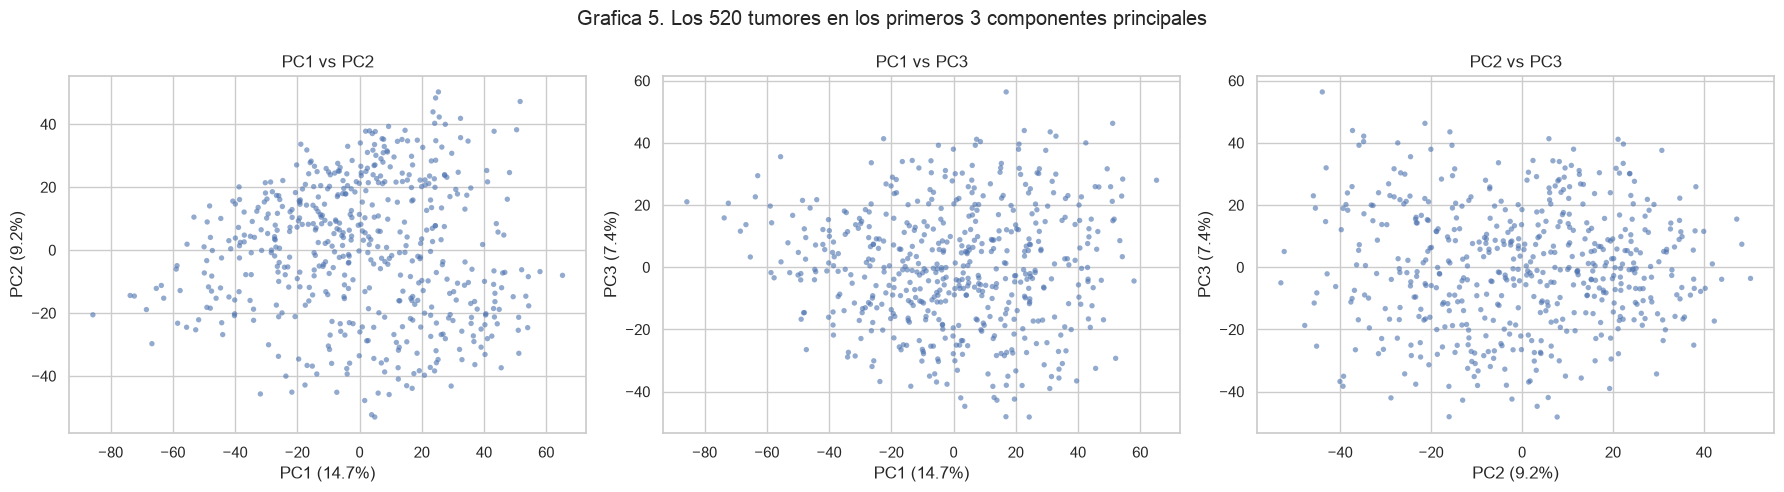

In [ ]:
 
n_pc = 10
Z10 = Z[:, :n_pc]

fig, axes = plt.subplots(1, 3, figsize=(18, 5))
for ax, (i, j) in zip(axes, [(0, 1), (0, 2), (1, 2)]):
    ax.scatter(Z[:, i], Z[:, j], s=15, alpha=0.6, color='#4C72B0', edgecolor='none')
    ax.set_xlabel(f'PC{i+1} ({pve[i]*100:.1f}%)')
    ax.set_ylabel(f'PC{j+1} ({pve[j]*100:.1f}%)')
    ax.set_title(f'PC{i+1} vs PC{j+1}')
plt.suptitle('Grafica 5. Los 520 tumores en los primeros 3 componentes principales')
plt.tight_layout()
plt.show()

**No hay grupos separados como islas.** Los 520 tumores forman una sola nube continua en los tres planos. En PC1 vs PC2 la nube tiene forma de triángulo, con zonas más densas en la parte de arriba, a la izquierda y abajo a la derecha, pero sin huecos claros entre ellas.

Esto adelanta lo que se va a encontar: si existen subtipos, van a ser **regiones de un continuo** y no grupos perfectamente separados, así que la silueta de cualquier clustering va a ser baja. Es lo esperado en expresión génica de tumores, donde cada muestra es una mezcla de células tumorales, estroma y células inmunes en proporciones distintas.

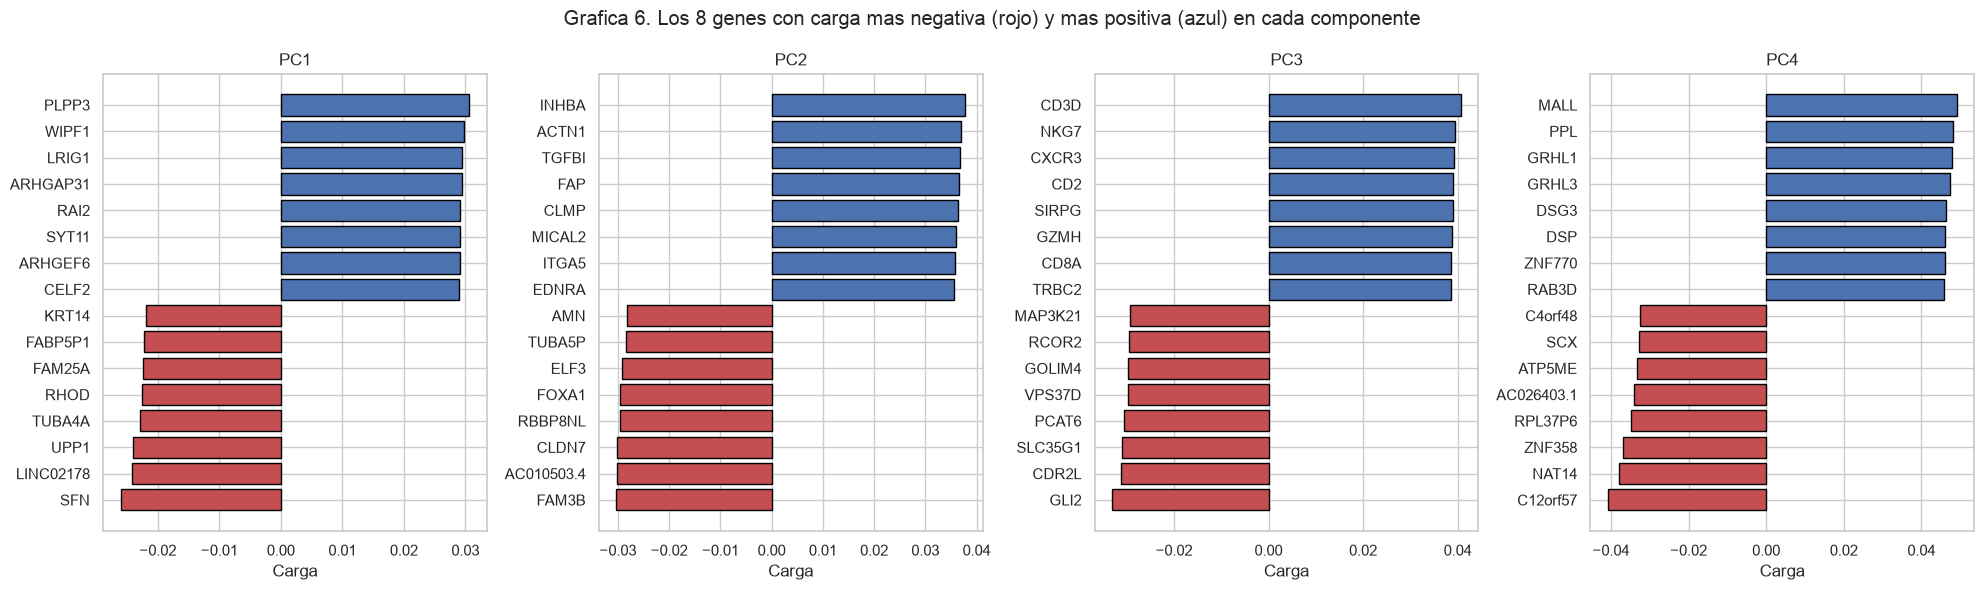

In [ ]:
 
cargas = pd.DataFrame(pca.components_[:4].T, index=mapa.loc[genes_top, 'gene'].values,
                      columns=['PC1', 'PC2', 'PC3', 'PC4'])

fig, axes = plt.subplots(1, 4, figsize=(20, 6))
for ax, pc in zip(axes, cargas.columns):
    orden = cargas[pc].sort_values()
    sel = pd.concat([orden.head(8), orden.tail(8)])
    ax.barh(sel.index, sel.values, color=['#C44E52' if v < 0 else '#4C72B0' for v in sel.values], edgecolor='black')
    ax.set_title(pc)
    ax.set_xlabel('Carga')
plt.suptitle('Grafica 6. Los 8 genes con carga mas negativa (rojo) y mas positiva (azul) en cada componente')
plt.tight_layout()
plt.show()

Las cargas muestran qué representa cada eje:

- **PC1 (14.7%), epitelio tumoral contra microambiente.** En el lado negativo están genes del epitelio escamoso (SFN, KRT14, S100A12, FABP5); en el positivo, genes de células no epiteliales, como leucocitos y vasos (PREX1, BCL2, ARHGEF6, RASSF2). Es un eje de **pureza**: qué tanto de la muestra es tumor y qué tanto es tejido que lo rodea.
- **PC2 (9.2%), fibroblastos contra epitelio glandular.** En el lado positivo están genes de fibroblastos asociados al cáncer y de transición epitelio-mesénquima (INHBA, FAP, TGFBI, COL5A1, CALD1); en el negativo, genes de epitelio diferenciado (FOXA1, CLDN7, ELF3, FAM3B).
- **PC3 (7.4%), infiltración de linfocitos T.** Su lado positivo son genes de linfocitos T citotóxicos (CD3D, CD8A, NKG7, GZMB, PDCD1).
- **PC4 (5.7%), diferenciación escamosa.** Su lado positivo son genes de desmosomas y diferenciación (DSG3, DSP, PPL, GRHL1, GRHL3).

Los ejes que más varianza explican no son "genes del cáncer" sino **la composición de cada muestra**: cuánto epitelio, cuánto estroma y cuántas células inmunes trae. Los subtipos que se encuentren van a estar definidos tanto por las células tumorales como por su microambiente.

# Construcción y comparación de modelos de clustering

Los dos métodos se aplican sobre la misma matriz: los **10 primeros componentes principales** de los 520 tumores.

## K-means

Vamos a agrupar los tumores con K-means sobre los 10 componentes. Primero se elige el número de clusters con la silueta y la inercia, y después se ajusta el modelo y se revisa qué tan estable es.

### Número de clusters

Se corre K-means con $K$ de 2 a 8 (con n_init=50) y se calculan la inercia y la silueta promedio de cada solución.

 K   Inercia  Silueta
 2 1077512.0    0.171
 3  930830.0    0.166
 4  836094.0    0.181
 5  772145.0    0.157
 6  723003.0    0.156
 7  677570.0    0.164
 8  641134.0    0.161


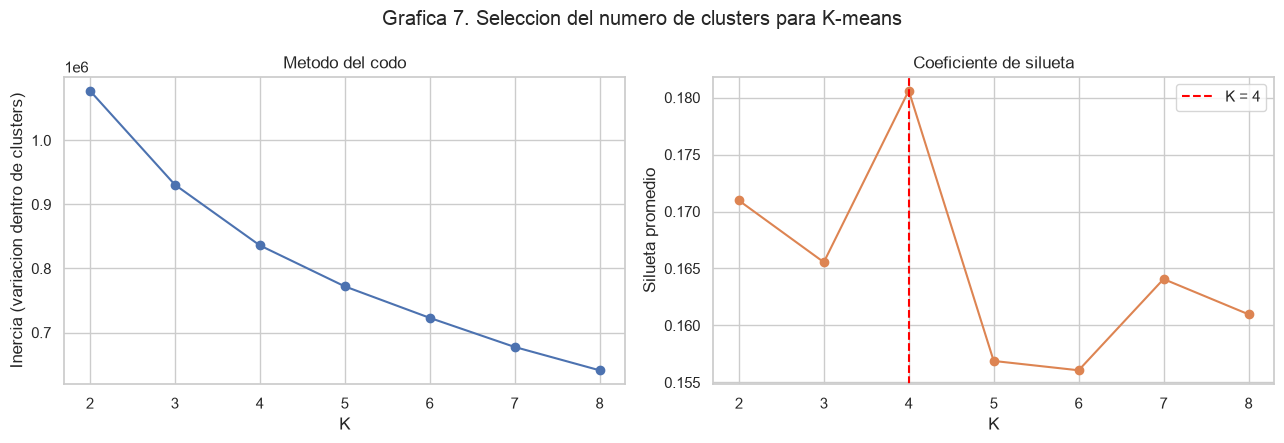

In [ ]:
 
ks = list(range(2, 9))
inercias, siluetas = [], []
for k in ks:
    km = KMeans(n_clusters=k, n_init=50, random_state=67).fit(Z10)
    inercias.append(km.inertia_)
    siluetas.append(silhouette_score(Z10, km.labels_))

print(pd.DataFrame({'K': ks, 'Inercia': np.round(inercias, 0), 'Silueta': np.round(siluetas, 3)}).to_string(index=False))

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
axes[0].plot(ks, inercias, marker='o', color='#4C72B0')
axes[0].set_xlabel('K')
axes[0].set_ylabel('Inercia (variacion dentro de clusters)')
axes[0].set_title('Metodo del codo')
axes[1].plot(ks, siluetas, marker='o', color='#DD8452')
axes[1].axvline(4, color='red', linestyle='--', label='K = 4')
axes[1].set_xlabel('K')
axes[1].set_ylabel('Silueta promedio')
axes[1].set_title('Coeficiente de silueta')
axes[1].legend()
plt.suptitle('Grafica 7. Seleccion del numero de clusters para K-means')
plt.tight_layout()
plt.show()

- **La inercia baja de forma suave**, sin un codo claro: siempre baja al agregar clusters, y aquí no hay un punto donde deje de bajar de golpe. Por sí sola no sirve para elegir.
- **La silueta tiene su máximo en K = 4 (0.181)**, por arriba de K = 2 (0.171), K = 3 (0.166) y de todas las soluciones con 5 o más clusters (0.164 o menos).

Entonces vamos a escoger:

**K = 4**

La silueta de 0.181 es baja en términos absolutos, pero es lo esperado después de ver que los tumores forman un continuo (Gráfica 5): los clusters son regiones de la nube y los tumores de las fronteras quedan cerca de dos grupos.

Tumores por cluster:
1    164
2    163
3    124
4     69

Silueta promedio: 0.181


ARI contra 5 semillas distintas: [0.996 0.887 0.996 0.942 1.   ]
ARI contra K-means con 6 componentes: 0.849
ARI contra K-means con 15 componentes: 0.974


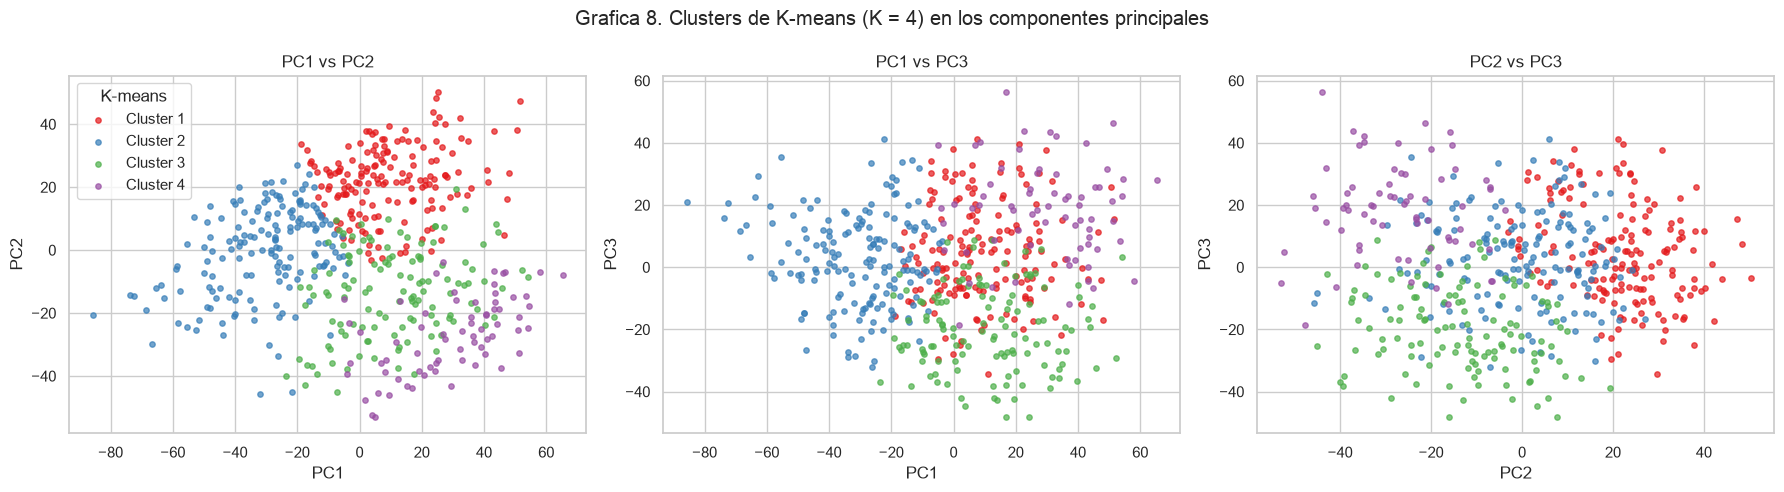

In [ ]:
 
K = 4
kmeans = KMeans(n_clusters=K, n_init=50, random_state=67).fit(Z10)

# Se numeran los clusters del mas grande (1) al mas chico (4)
orden_tamano = pd.Series(kmeans.labels_).value_counts().index
renumerar = {viejo: nuevo for nuevo, viejo in enumerate(orden_tamano, start=1)}
cluster_km = pd.Series(kmeans.labels_, index=tumores).map(renumerar)
print("Tumores por cluster:")
print(cluster_km.value_counts().sort_index().to_string())
print(f"\nSilueta promedio: {silhouette_score(Z10, cluster_km):.3f}")

# Estabilidad: la misma K con otras semillas y con otro numero de componentes
ari_semillas = [adjusted_rand_score(cluster_km, KMeans(n_clusters=K, n_init=50, random_state=s).fit_predict(Z10))
                for s in [1, 2, 3, 4, 5]]
print("ARI contra 5 semillas distintas:", np.round(ari_semillas, 3))
for n in [6, 15]:
    otra = KMeans(n_clusters=K, n_init=50, random_state=67).fit_predict(Z[:, :n])
    print(f"ARI contra K-means con {n} componentes: {adjusted_rand_score(cluster_km, otra):.3f}")

colores = {1: '#E41A1C', 2: '#377EB8', 3: '#4DAF4A', 4: '#984EA3'}
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
for ax, (i, j) in zip(axes, [(0, 1), (0, 2), (1, 2)]):
    for c in range(1, K + 1):
        m = (cluster_km == c).values
        ax.scatter(Z[m, i], Z[m, j], s=15, alpha=0.7, color=colores[c], label=f'Cluster {c}')
    ax.set_xlabel(f'PC{i+1}')
    ax.set_ylabel(f'PC{j+1}')
    ax.set_title(f'PC{i+1} vs PC{j+1}')
axes[0].legend(title='K-means')
plt.suptitle('Grafica 8. Clusters de K-means (K = 4) en los componentes principales')
plt.tight_layout()
plt.show()

Los 4 clusters tienen **164, 163, 124 y 69 tumores** (se numeran del más grande al más chico). Antes de interpretarlos se revisa que sean estables:

- **Contra otras 5 semillas**, el ARI (*adjusted Rand index*, 1 = misma partición, 0 = coincidencia al azar) va de 0.887 a 1.0, y en 3 de las 5 es de 0.99 o más. Los clusters no dependen del inicio aleatorio.
- **Con 15 componentes en vez de 10**, el ARI es de 0.974: prácticamente los mismos clusters. Con 6 componentes es de 0.849. La decisión de usar 10 componentes no está cambiando el resultado.

En el plano PC1 vs PC2 cada cluster ocupa una región de la nube: el **cluster 1** arriba (PC2 alto, fibroblastos), el **cluster 2** a la izquierda (PC1 bajo, epitelio), el **cluster 3** abajo al centro y el **cluster 4** abajo a la derecha. En PC2 vs PC3, el cluster 4 se separa hacia arriba (PC3 alto, linfocitos T). Las fronteras se tocan, como se esperaba.

## Clustering jerárquico

Se construye el dendrograma con los 3 métodos de linkage sobre los mismos 10 componentes y distancia euclideana.

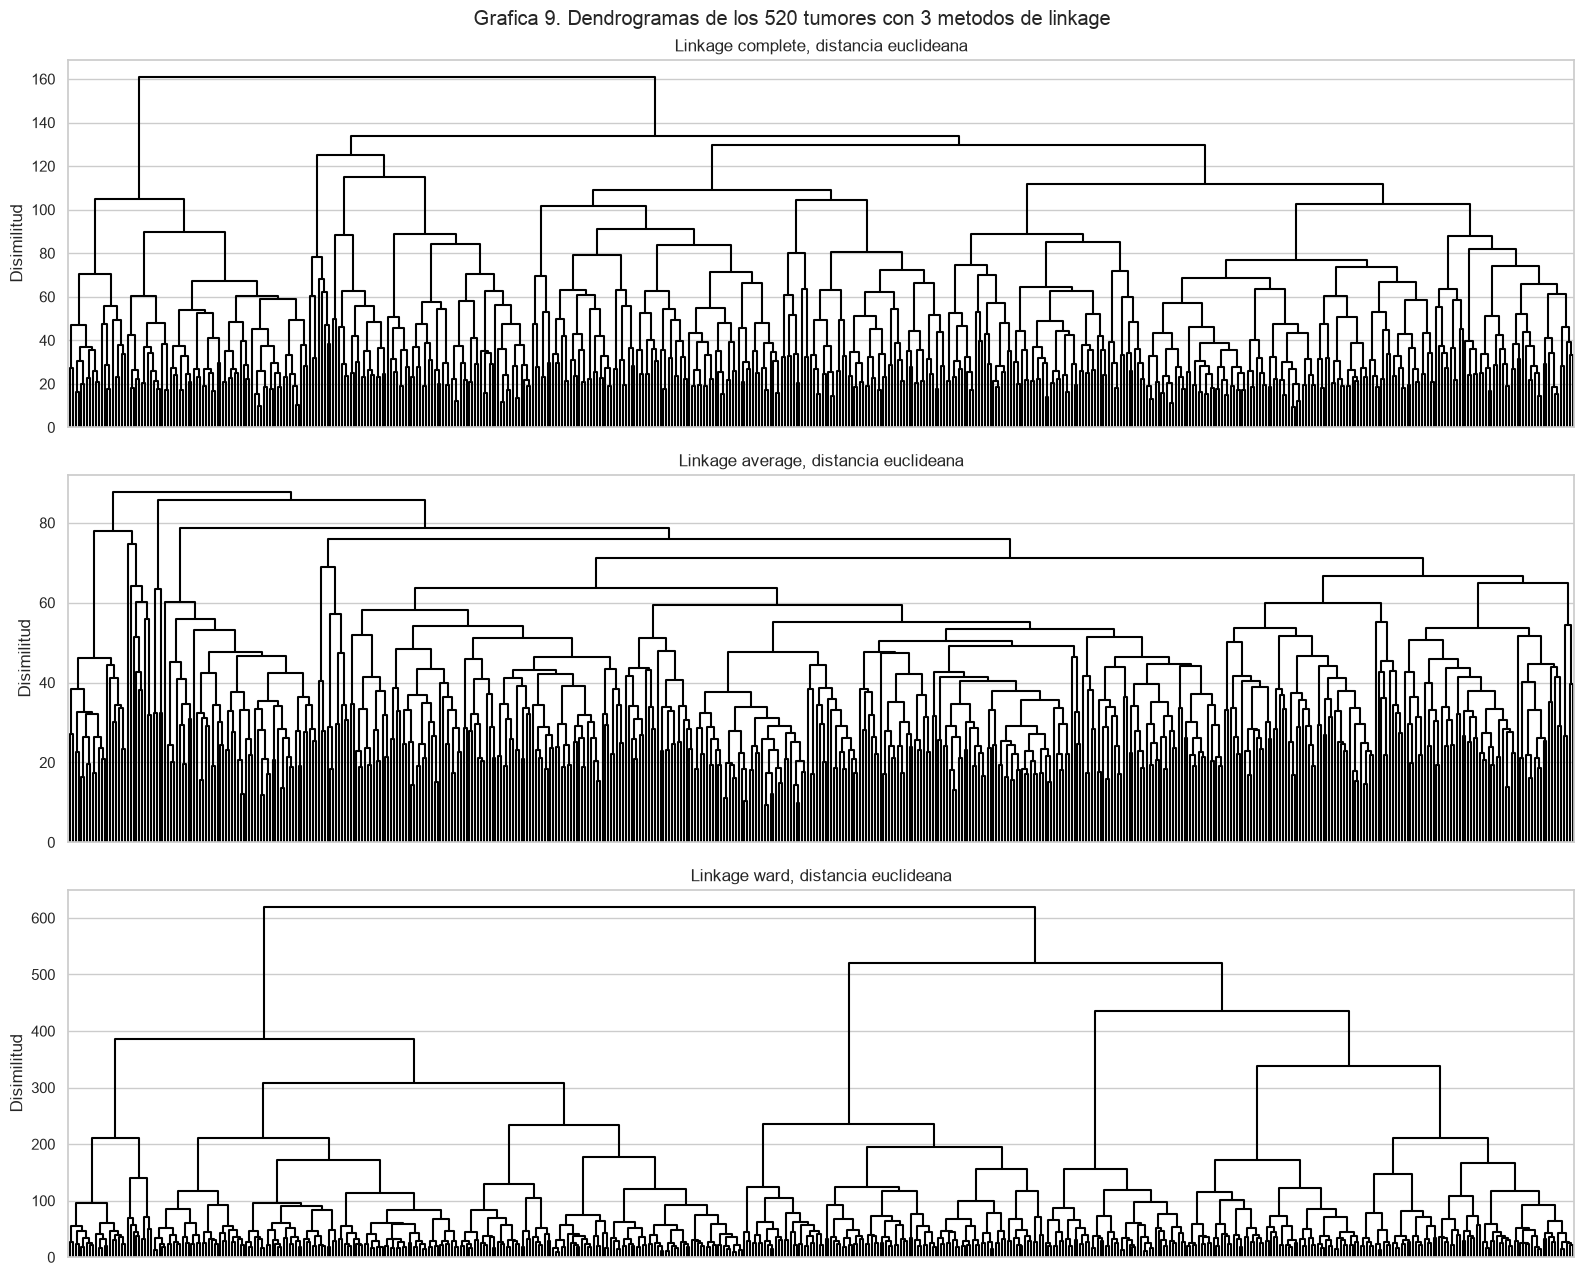

Tamano de los clusters al cortar cada dendrograma en 4:
  complete : [217, 143, 83, 77]
  average  : [434, 53, 29, 4]
  ward     : [233, 134, 104, 49]


In [ ]:
 
metodos = ['complete', 'average', 'ward']
enlaces = {m: linkage(Z10, method=m, metric='euclidean') for m in metodos}

set_link_color_palette(['black'])
fig, axes = plt.subplots(3, 1, figsize=(16, 13))
for ax, m in zip(axes, metodos):
    dendrogram(enlaces[m], ax=ax, no_labels=True, color_threshold=0, above_threshold_color='black')
    ax.set_title(f'Linkage {m}, distancia euclideana')
    ax.set_ylabel('Disimilitud')
plt.suptitle('Grafica 9. Dendrogramas de los 520 tumores con 3 metodos de linkage')
plt.tight_layout()
plt.show()

print("Tamano de los clusters al cortar cada dendrograma en 4:")
for m in metodos:
    print(f"  {m:<9}: {sorted(np.bincount(fcluster(enlaces[m], K, criterion='maxclust'))[1:].tolist(), reverse=True)}")

- **Average:** al cortar en 4 queda un cluster gigante de 434 tumores (83%) y tres chiquitos (53, 29 y 4). Es el efecto de **encadenamiento**: el dendrograma tiene forma de escalera y va pegnado tumores sueltos a un grupo que no deja de crecer. No sirve para encontrar subtipos.
- **Complete:** da tamaños más parejos (217, 143, 83 y 77), pero su silueta con 4 clusters es la más baja de los tres métodos (0.091). Como une grupos según su par de tumores **más lejano**, un solo tumor raro decide cuándo se unen dos grupos.
- **Ward:** da el dendrograma más balanceado, con ramas largas y bien definidas arriba, y la mejor silueta de los tres (0.149). Además minimiza la misma variación dentro de clusters que K-means, así que la comparación entre métodos es directa.

**Se usa linkage Ward.** Ahora hay que decidir dónde cortarlo.

 Clusters Corte entre las alturas  Tamano del intervalo
        2           520.8 y 619.3                  98.4
        3           436.0 y 520.8                  84.8
        4           385.4 y 436.0                  50.6
        5           339.0 y 385.4                  46.4
        6           307.8 y 339.0                  31.3
        7           235.9 y 307.8                  71.8
        8           234.7 y 235.9                   1.3
        9           211.7 y 234.7                  23.0

Tumores por cluster (Ward):
1    233
2    134
3    104
4     49


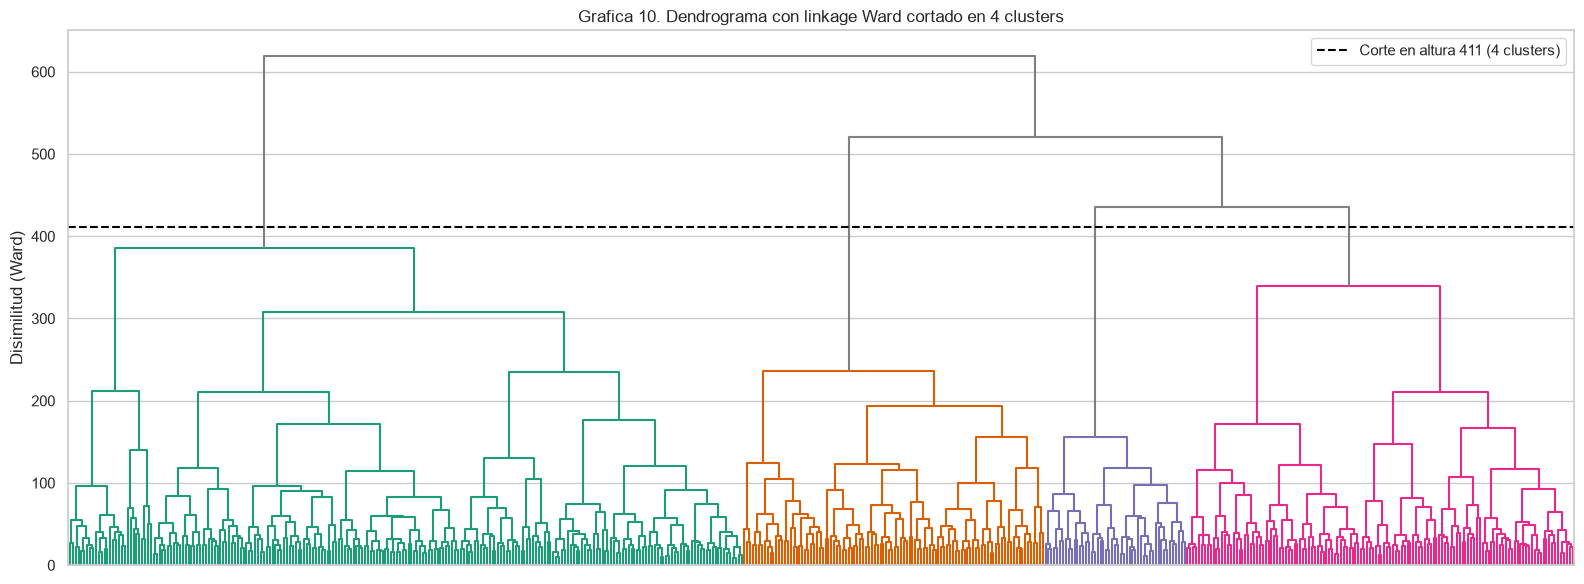

In [ ]:
 
alturas = np.sort(enlaces['ward'][:, 2])[::-1][:9]      # alturas de las ultimas 9 uniones, de mayor a menor
print(pd.DataFrame({
    'Clusters': range(2, 10),
    'Corte entre las alturas': [f'{alturas[i+1]:.1f} y {alturas[i]:.1f}' for i in range(8)],
    'Tamano del intervalo': (alturas[:-1] - alturas[1:]).round(1),
}).to_string(index=False))

corte = (alturas[2] + alturas[3]) / 2                   # punto medio del intervalo que deja 4 clusters
cluster_hc = pd.Series(fcluster(enlaces['ward'], K, criterion='maxclust'), index=tumores)
orden_tamano = cluster_hc.value_counts().index
cluster_hc = cluster_hc.map({viejo: nuevo for nuevo, viejo in enumerate(orden_tamano, start=1)})
print("\nTumores por cluster (Ward):")
print(cluster_hc.value_counts().sort_index().to_string())

colores_hc = {1: '#1B9E77', 2: '#D95F02', 3: '#7570B3', 4: '#E7298A'}
set_link_color_palette(list(colores_hc.values()))
fig, ax = plt.subplots(figsize=(16, 6))
dendrogram(enlaces['ward'], ax=ax, no_labels=True, color_threshold=corte, above_threshold_color='gray')
ax.axhline(corte, color='black', linestyle='--', label=f'Corte en altura {corte:.0f} (4 clusters)')
ax.set_ylabel('Disimilitud (Ward)')
ax.legend()
plt.title('Grafica 10. Dendrograma con linkage Ward cortado en 4 clusters')
plt.tight_layout()
plt.show()
set_link_color_palette(None)

Los intervalos más grandes del dendrograma de Ward están en **2 clusters (98.4) y 3 clusters (84.8)**; el de 4 clusters mide 50.6. **Se corta en 4 clusters** por dos razones:

1. **El corte en 4 es el que separa un grupo compacto de 49 tumores** que en los cortes de 2 y 3 queda metido dentro de un grupo grande. Con 2 o 3 clusters, ese grupo se mezcla con otros tumores que tienen un perfil muy distinto (en la sección de comparación se ve que coincide casi completo con el cluster 4 de K-means, el que tiene el perfil génico más marcado).
2. **Con el mismo $K$ los dos métodos se pueden comparar directamente.** Si Ward se cortara en 2 y K-means en 4, cualquier diferencia vendría del número de clusters y no del método.

Con el corte en 4, los clusters de Ward tienen **233, 134, 104 y 49 tumores**.

## Comparación de K-means y clustering jerárquico

Vamos a cruzar los clusters de los dos métodos en una tabla y a calcular el ARI y la silueta de cada uno, para ver en qué grupos coinciden y en cuáles no.

Ward       1    2    3   4  All
K-means                        
1         65    2   97   0  164
2        150   13    0   0  163
3         14  103    6   1  124
4          4   16    1  48   69
All      233  134  104  49  520

ARI entre K-means y Ward: 0.468
Silueta K-means: 0.181 | Silueta Ward: 0.149


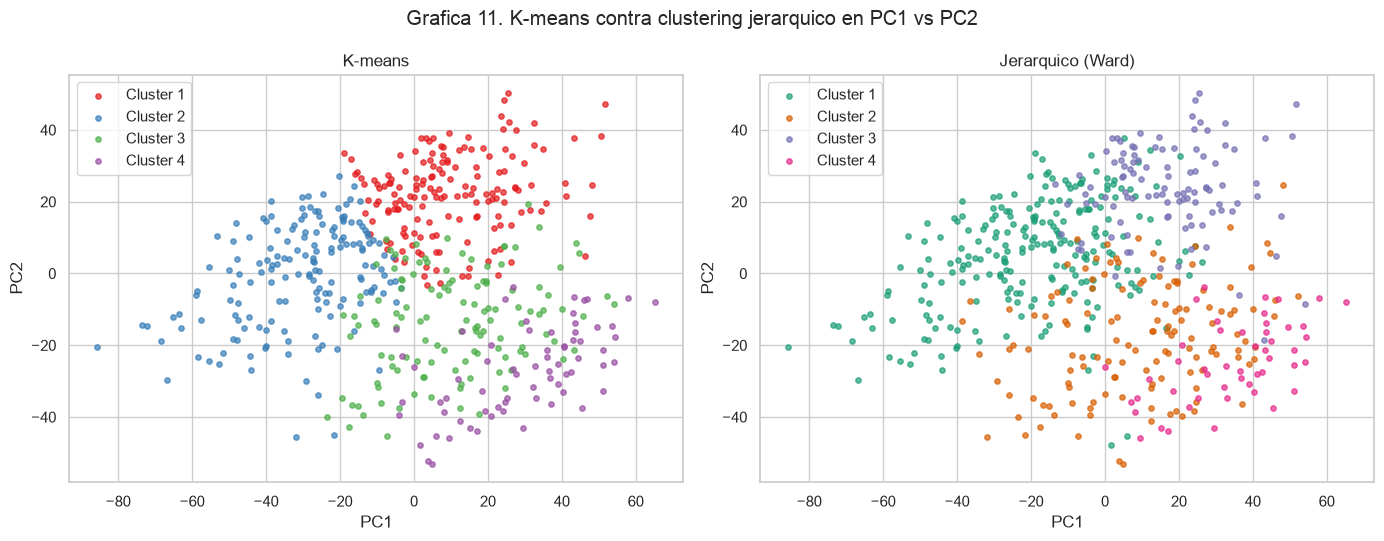

In [ ]:
 
print(pd.crosstab(cluster_km, cluster_hc, rownames=['K-means'], colnames=['Ward'], margins=True))
print(f"\nARI entre K-means y Ward: {adjusted_rand_score(cluster_km, cluster_hc):.3f}")
print(f"Silueta K-means: {silhouette_score(Z10, cluster_km):.3f} | Silueta Ward: {silhouette_score(Z10, cluster_hc):.3f}")

fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))
for ax, etiquetas, pal, titulo in [(axes[0], cluster_km, colores, 'K-means'), (axes[1], cluster_hc, colores_hc, 'Jerarquico (Ward)')]:
    for c in range(1, K + 1):
        m = (etiquetas == c).values
        ax.scatter(Z[m, 0], Z[m, 1], s=15, alpha=0.7, color=pal[c], label=f'Cluster {c}')
    ax.set_xlabel('PC1')
    ax.set_ylabel('PC2')
    ax.set_title(titulo)
    ax.legend()
plt.suptitle('Grafica 11. K-means contra clustering jerarquico en PC1 vs PC2')
plt.tight_layout()
plt.show()

El ARI entre los dos métodos es de **0.468**: coinciden más que al azar, pero no son la misma partición. Revisando la tabla cruzada:

**Similitudes:**

- **El cluster 4 de Ward (49 tumores) es el cluster 4 de K-means:** 48 de sus 49 tumores están en el cluster 4 de K-means. Los dos métodos encuentran este grupo.
- **El cluster 3 de Ward (104) corresponde al cluster 1 de K-means:** 97 de sus 104 tumores.
- **El cluster 2 de Ward (134) corresponde al cluster 3 de K-means:** 103 de sus 134 tumores.

**Diferencias:**

- **El cluster más grande de Ward (233) junta dos grupos de K-means:** 150 tumores del cluster 2 y 65 del cluster 1.
- **El cluster 1 de K-means (164) queda partido en Ward:** 97 tumores forman su propio cluster y 65 se van al cluster grande.
- **16 tumores del cluster 4 de K-means quedan en el cluster 2 de Ward.**

**¿Por qué pasa?** Ward es un método **voraz**: cada unión es definitiva. Si en las primeras uniones (abajo del dendrograma) un tumor de frontera se pega a un grupo, ahí se queda aunque al final quede más cerca del centroide de otro. K-means, en cambio, reasigna cada tumor al centroide más cercano en cada iteración, así que corrige esas fronteras. Además, el clustering jerárquico obliga a que los clusters estén anidados (el de 4 sale de partir uno de los de 3), algo que no tiene por qué cumplirse cuando los grupos son regiones de un continuo.

## Selección del modelo final

Con la comparación anterior se escoge un solo modelo, que es el que se usa para el análisis de genes y el clínico.

**El modelo final es K-means con K = 4.** La decisión se justifica así:

- **Mejor separación:** silueta de 0.181 contra 0.149 de Ward con el mismo $K$.
- **Más estable:** da casi la misma partición con otras semillas (ARI de 0.887 a 1.0) y con 15 componentes (ARI de 0.974).
- **Grupos más balanceados y sin mezclar:** Ward junta en un solo cluster de 233 tumores dos grupos que K-means separa, y que en la siguiente sección resultan tener perfiles génicos muy distintos.
- **Los dos métodos coinciden en los grupos más definidos** (sobre todo el cluster 4), así que K-means no está inventando estructura que el otro método no vea.

Desde aquí, todo el análisis usa los clusters de K-means.

# Interpretación de los clusters - análisis de genes

Para cada cluster se compara cada uno de los **20,948 genes** contra los demás tumores con la prueba t de Welch, se corrigen los p-values con Benjamini-Hochberg y se calcula el log2FC. Un gen es diferencial si tiene **q < 0.05 y |log2FC| ≥ 1** (el doble o la mitad de expresión).

In [ ]:
 
simbolo = mapa.loc[datos.index, 'gene']
resultados = []
for c in range(1, K + 1):
    dentro = datos.loc[:, (cluster_km == c).values].values
    fuera = datos.loc[:, (cluster_km != c).values].values
    t, p = stats.ttest_ind(dentro, fuera, axis=1, equal_var=False)
    p = np.nan_to_num(p, nan=1.0)
    resultados.append(pd.DataFrame({
        'Cluster': c, 'Ensembl': datos.index, 'Gen': simbolo.values,
        'log2FC': dentro.mean(axis=1) - fuera.mean(axis=1),
        'p': p, 'q': stats.false_discovery_control(p),
    }))
de = pd.concat(resultados, ignore_index=True)
de['Diferencial'] = (de['q'] < 0.05) & (de['log2FC'].abs() >= 1)

print(f"Genes probados por cluster: {len(datos):,}")
print(f"Pruebas con p < 0.05 sin corregir: {(de['p'] < 0.05).sum():,} | con q < 0.05: {(de['q'] < 0.05).sum():,}")
sig = de[de['Diferencial']].copy()
sig['Direccion'] = np.where(sig['log2FC'] > 0, 'Mas expresados', 'Menos expresados')
pd.crosstab(sig['Cluster'], sig['Direccion'], margins=True)

Genes probados por cluster: 20,948
Pruebas con p < 0.05 sin corregir: 61,331 | con q < 0.05: 59,643


Direccion,Mas expresados,Menos expresados,All
Cluster,,,
1,599,68,667
2,152,1129,1281
3,519,106,625
4,1208,612,1820
All,2478,1915,4393


De las 83,792 pruebas (20,948 genes × 4 clusters), **61,331 tienen p < 0.05 sin corregir y 59,643 siguen siendo significativas después de la corrección**. Con 520 tumores casi cualqueir diferencia, por chica que sea, es estadísticamente significativa; por eso también se exige un **|log2FC| ≥ 1**, para quedarse con diferencias biológicamente grandes. Con los dos criterios quedan **4,393 genes diferenciales**:

- **Cluster 1:** 599 más expresados y 68 menos.
- **Cluster 2:** pocos más expresados (152) y muchos menos expresados (1,129).
- **Cluster 3:** 519 más expresados y 106 menos.
- **Cluster 4:** el más distinto de todos, con 1,208 más expresados y 612 menos.

In [ ]:
 
top_genes = (de[de['Diferencial'] & (de['log2FC'] > 0)]
             .sort_values(['Cluster', 'log2FC'], ascending=[True, False])
             .groupby('Cluster').head(10))
tabla_top = pd.DataFrame({
    f'Cluster {c}': [f"{g} ({fc:.1f})" for g, fc in top_genes.loc[top_genes['Cluster'] == c, ['Gen', 'log2FC']].values]
    for c in range(1, K + 1)
}, index=range(1, 11))
tabla_top

,Cluster 1,Cluster 2,Cluster 3,Cluster 4
1,ACTA1 (3.5),KRTDAP (2.8),NTS (4.3),FDCSP (5.7)
2,DES (3.5),SPRR2G (2.7),UPK1B (3.7),KRT19 (4.4)
3,ACTC1 (3.3),KRT1 (2.7),KRT19 (3.6),IGHM (3.9)
4,MMP13 (3.2),S100A7 (2.6),GPX2 (3.6),FAM3B (3.5)
5,MYL1 (3.2),LCE3D (2.6),ALDH3A1 (3.4),GABRP (3.4)
6,MYBPH (3.1),KRT6C (2.5),GSTA1 (3.4),IGKV4-1 (3.4)
7,MYL2 (3.0),CRCT1 (2.5),NTRK2 (3.3),IGLV2-14 (3.4)
8,CKM (2.9),PI3 (2.4),ALDH1A1 (3.2),IGLV4-69 (3.3)
9,CSRP3 (2.7),SPRR2B (2.4),SOX2 (3.1),IGKC (3.3)
10,SLN (2.7),LCE3E (2.4),AC090004.2 (3.1),IGHG1 (3.3)


La tabla muestra los 10 genes más sobreexpresados de cada cluster con su log2FC entre paréntesis (un log2FC de 3 quiere decir 8 veces más expresión). El heatmap muestra esos 40 genes en los 520 tumores.

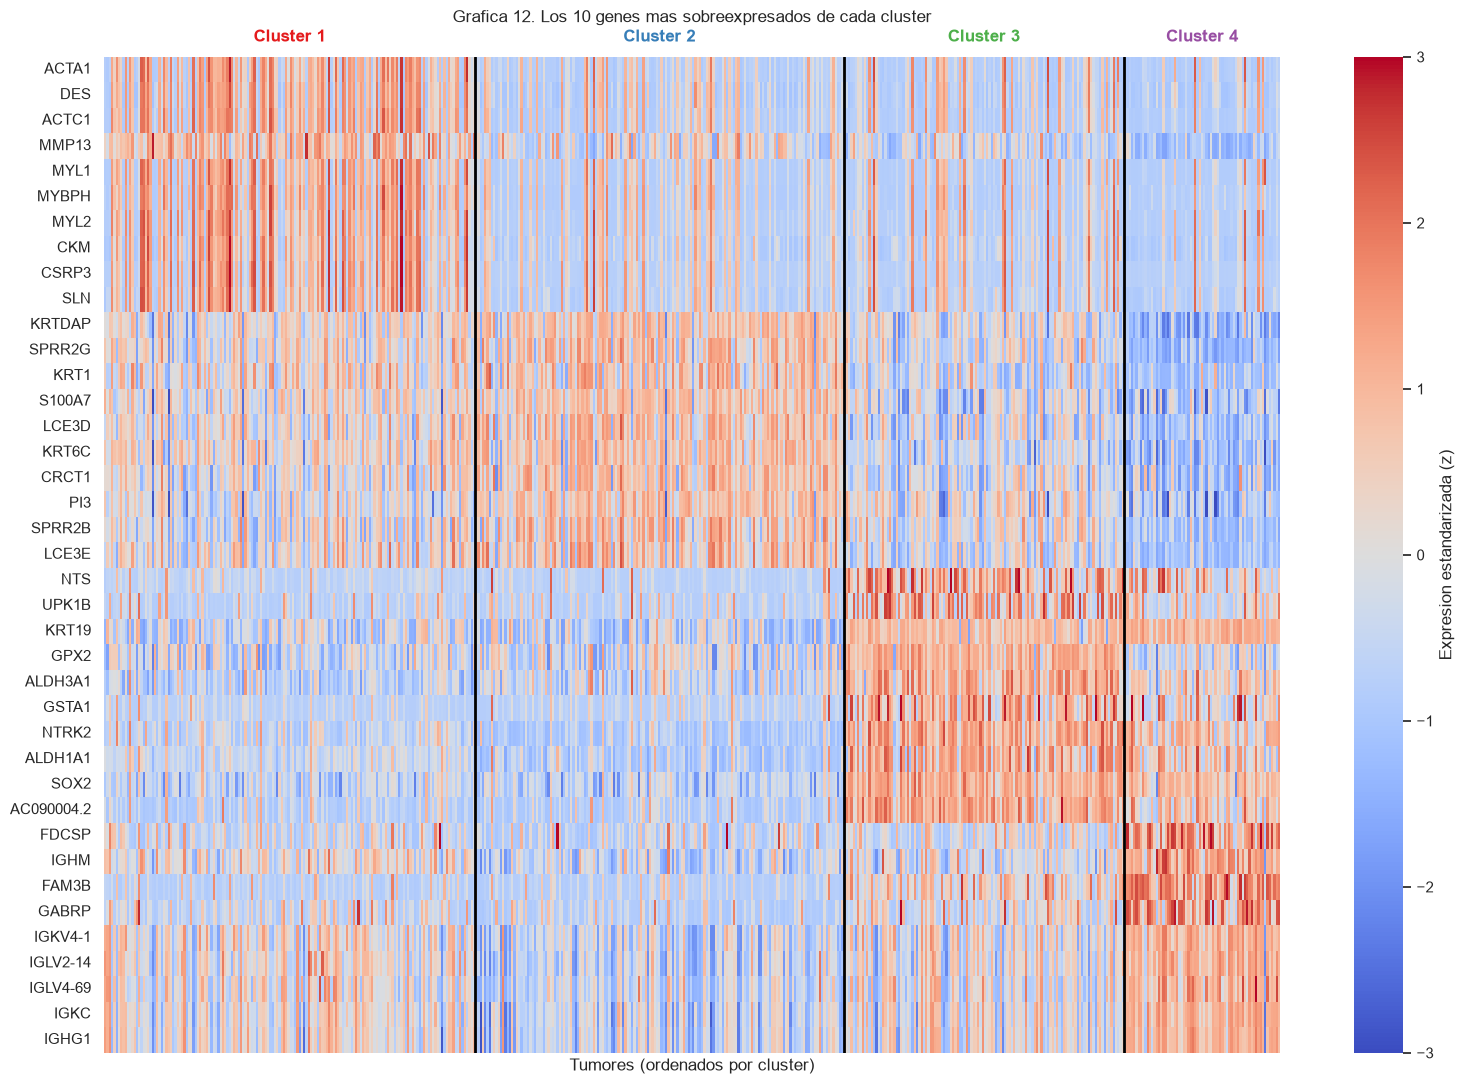

In [ ]:
 
genes_heatmap = top_genes['Ensembl'].drop_duplicates()
orden_muestras = cluster_km.sort_values(kind='stable').index
z_heat = datos.loc[genes_heatmap, orden_muestras]
z_heat = z_heat.sub(z_heat.mean(axis=1), axis=0).div(z_heat.std(axis=1), axis=0).clip(-3, 3)
z_heat.index = mapa.loc[genes_heatmap, 'gene'].values

fig, ax = plt.subplots(figsize=(16, 11))
sns.heatmap(z_heat, cmap='coolwarm', center=0, ax=ax, xticklabels=False,
            cbar_kws={'label': 'Expresion estandarizada (z)'})
limites = np.cumsum(cluster_km.value_counts().sort_index().values)
inicios = np.concatenate([[0], limites[:-1]])
for x in limites[:-1]:
    ax.axvline(x, color='black', linewidth=2)
for c, (a, b) in enumerate(zip(inicios, limites), start=1):
    ax.text((a + b) / 2, -0.6, f'Cluster {c}', ha='center', fontweight='bold', color=colores[c])
ax.set_xlabel('Tumores (ordenados por cluster)')
ax.set_title('Grafica 12. Los 10 genes mas sobreexpresados de cada cluster', pad=25)
plt.tight_layout()
plt.show()

Cada cluster tiene un bloque de genes propio, y casi todos sus tumores lo comparten:

- **Cluster 1 (164), estroma y músculo:** genes de **músculo esquelético** (ACTA1, DES, ACTC1, MYL1, MYL2, CKM), de **matriz extracelular y estroma** (FN1, COL3A1, POSTN, SFRP2) y metaloproteasas de invasión (MMP13, MMP1). Tiene poco de los genes de diferenciación del epitelio (SPRR3, KRT13, SOX2). Es el cluster con más tejido que rodea al tumor (fibroblastos y músculo).
- **Cluster 2 (163), queratinización:** genes de **diferenciación terminal del epitelio escamoso**: queratinas KRT1, KRT6C, KRT14 y KRT16, la familia SPRR, LCE3, KRTDAP y la proteína antimicrobiana S100A7. Tiene **muy pocas células inmunes**: entre sus 1,129 genes menos expresados están decenas de inmunoglobulinas (IGHV, IGLV).
- **Cluster 3 (124), metabolismo de xenobióticos:** genes que procesan tóxicos y responden al **estrés oxidativo** (GPX2, ALDH3A1, GSTA1, AKR1C1, AKR1C2, AKR1C3, CYP4F11, UGT1A7), muchos de ellos activados por la vía NRF2. También el factor de transcripción **SOX2** y NTS. Tiene poca señal inmune (CXCL9, CXCL10 y CXCL11 están entre sus genes menos expresados).
- **Cluster 4 (69), linfocitos B y epitelio no queratinizado:** FDCSP, decenas de **inmunoglobulinas** (IGHM, IGKC, IGHG1, IGHA1) y CD79A, que vienen de **linfocitos B y células plasmáticas**, más KRT19, FAM3B y GABRP. Es el opuesto del cluster 2: tiene **los genes de queratinización más bajos de todos** (KRTDAP, KRT14, KRT1, SPRR2G).

### Panel de genes de referencia

Para ponerle nombre a cada cluster, se revisa un panel de genes conocidos en este cáncer. Los subtipos de expresión de HNSC descritos en la literatura (Walter et al., 2013; TCGA, 2015) son **atípico** (asociado al VPH), **clásico** (estrés oxidativo y tabaco), **mesenquimal** (estroma) y **basal** (genes de la capa basal del epitelio, como KRT14 y TGFA). Se calcula el promedio estandarizado de la firma de cada subtipo en cada cluster, y se asigna a cada cluster un subtipo distinto buscando la combinación con el mayor puntaje total (asignación óptima con linear_sum_assignment).

La firma atípica usa CDKN2A (p16), que en la clínica es el marcador indirecto de infección por VPH (se dispara cuando la proteína E7 del virus inactiva a RB), y SYCP2 y RPA2, que se reportan sobreexpresados en los tumores VPH positivos. El panel también incluye genes de linfocitos, músculo y queratinización para describir el resto de la composición.

Puntaje promedio (z) de cada firma en cada cluster:
   Atipico  Clasico  Mesenquimal  Basal
1    -0.24    -0.29         0.77   0.31
2    -0.38    -0.12        -0.59   0.24
3     0.05     0.86        -0.09  -0.17
4     1.38    -0.56        -0.30  -1.00

Nombre asignado: {1: 'C1 Mesenquimal', 2: 'C2 Basal', 3: 'C3 Clasico', 4: 'C4 Atipico'}


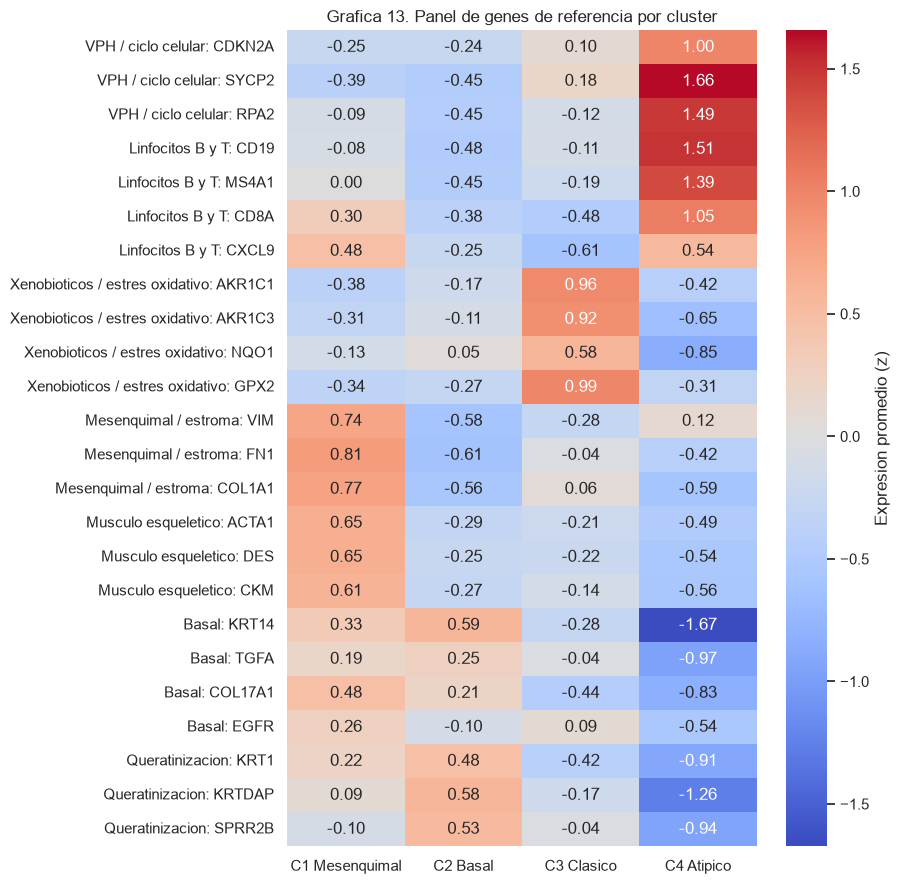

In [ ]:
 
panel = {
    'VPH / ciclo celular': ['CDKN2A', 'SYCP2', 'RPA2'],
    'Linfocitos B y T': ['CD19', 'MS4A1', 'CD8A', 'CXCL9'],
    'Xenobioticos / estres oxidativo': ['AKR1C1', 'AKR1C3', 'NQO1', 'GPX2'],
    'Mesenquimal / estroma': ['VIM', 'FN1', 'COL1A1'],
    'Musculo esqueletico': ['ACTA1', 'DES', 'CKM'],
    'Basal': ['KRT14', 'TGFA', 'COL17A1', 'EGFR'],
    'Queratinizacion': ['KRT1', 'KRTDAP', 'SPRR2B'],
}
id_por_gen = pd.Series(datos.index, index=simbolo.values)
id_por_gen = id_por_gen[~id_por_gen.index.duplicated()]
z_datos = datos.sub(datos.mean(axis=1), axis=0).div(datos.std(axis=1), axis=0)

filas = []
for grupo, genes in panel.items():
    for g in genes:
        filas.append(pd.Series(z_datos.loc[id_por_gen[g]].groupby(cluster_km.values).mean().values,
                               index=[f'Cluster {c}' for c in range(1, K + 1)], name=f'{grupo}: {g}'))
tabla_panel = pd.DataFrame(filas)

# Firma de cada subtipo de TCGA: promedio de sus genes; se asigna un subtipo distinto a cada cluster
firmas = {'Atipico': panel['VPH / ciclo celular'], 'Clasico': panel['Xenobioticos / estres oxidativo'],
          'Mesenquimal': panel['Mesenquimal / estroma'], 'Basal': panel['Basal']}
puntaje = pd.DataFrame({s: [z_datos.loc[id_por_gen[genes], (cluster_km == c).values].values.mean() for c in range(1, K + 1)]
                        for s, genes in firmas.items()}, index=range(1, K + 1))
filas_opt, cols_opt = linear_sum_assignment(-puntaje.values)
nombres = {int(puntaje.index[i]): f'C{puntaje.index[i]} {puntaje.columns[j]}' for i, j in zip(filas_opt, cols_opt)}
print("Puntaje promedio (z) de cada firma en cada cluster:")
print(puntaje.round(2))
print("\nNombre asignado:", nombres)

fig, ax = plt.subplots(figsize=(9, 9))
sns.heatmap(tabla_panel.rename(columns={f'Cluster {c}': nombres[c] for c in range(1, K + 1)}),
            cmap='coolwarm', center=0, annot=True, fmt='.2f', ax=ax, cbar_kws={'label': 'Expresion promedio (z)'})
ax.set_title('Grafica 13. Panel de genes de referencia por cluster')
plt.tight_layout()
plt.show()

La asignación es clara: en cada cluster, la firma más alta es la del subtipo que se le asignó.

- **C1 Mesenquimal:** firma mesenquimal de 0.77 (VIM, FN1, COL1A1), más la de músculo esquelético.
- **C2 Basal:** su única firma positiva es la basal (0.24). Tiene el KRT14 más alto de los 4 clusters (0.59), la queratinización más alta (KRT1, KRTDAP, SPRR2B) y casi no tiene linfocitos.
- **C3 Clásico:** firma clásica de 0.86 (AKR1C1, AKR1C3, GPX2, NQO1).
- **C4 Atípico:** firma de VPH de 1.38, la más fuerte de toda la tabla: **CDKN2A (p16) en 1.00, SYCP2 en 1.66 y RPA2 en 1.49**, junto con mucha infiltración de linfocitos B (CD19, MS4A1) y T (CD8A), y la firma basal más baja (KRT14 en -1.67).

**¿Qué quiere decir esto en palabras?** Sin ver ninguna variable clínica, el clustering encontró 4 grupos que coinciden con los 4 subtipos de expresión descritos para este cáncer. El más llamativo es **C4**: tiene el perfil molecular de un tumor causado por VPH (p16 alto, genes de ciclo celular activados, epitelio no queratinizado y muchos linfocitos B, típicos del tejido linfoide de la amígdala). Si es así, en la parte clínica debería concentrar tumores de orofaringe y pacientes con mejor supervivencia.

Desde aquí los clusters se llaman **C1 Mesenquimal, C2 Basal, C3 Clásico y C4 Atípico**.

# Interpretación de los clusters - análisis clínico

Ahora sí se cruzan los clusters con las variables clínicas. Primero las categóricas: sitio del tumor, sexo, etapa clínica y consumo de alcohol, con una prueba ji-cuadrada para cada una.

--- Sitio (% de cada cluster)
Sitio           Cavidad oral  Laringe e hipofaringe  Orofaringe  Sobrepuesto / sin especificar
Cluster                                                                                       
C1 Mesenquimal          60.4                   17.1         4.9                           17.7
C2 Basal                63.2                   12.3         8.0                           16.6
C3 Clasico              29.0                   52.4         7.3                           11.3
C4 Atipico              10.1                   17.4        69.6                            2.9 

--- Sexo (% de cada cluster)
Sexo            Hombre  Mujer
Cluster                      
C1 Mesenquimal    66.5   33.5
C2 Basal          69.9   30.1
C3 Clasico        79.0   21.0
C4 Atipico        91.3    8.7 

--- Etapa (% de cada cluster)
Etapa           I-II   III    IV
Cluster                         
C1 Mesenquimal  31.3  15.3  53.4
C2 Basal        23.5  22.9  53.6
C3 Clasico      18.9  28.

--- Alcohol (% de cada cluster)
Alcohol           No    Si
Cluster                   
C1 Mesenquimal  28.6  71.4
C2 Basal        36.9  63.1
C3 Clasico      35.0  65.0
C4 Atipico      22.1  77.9 



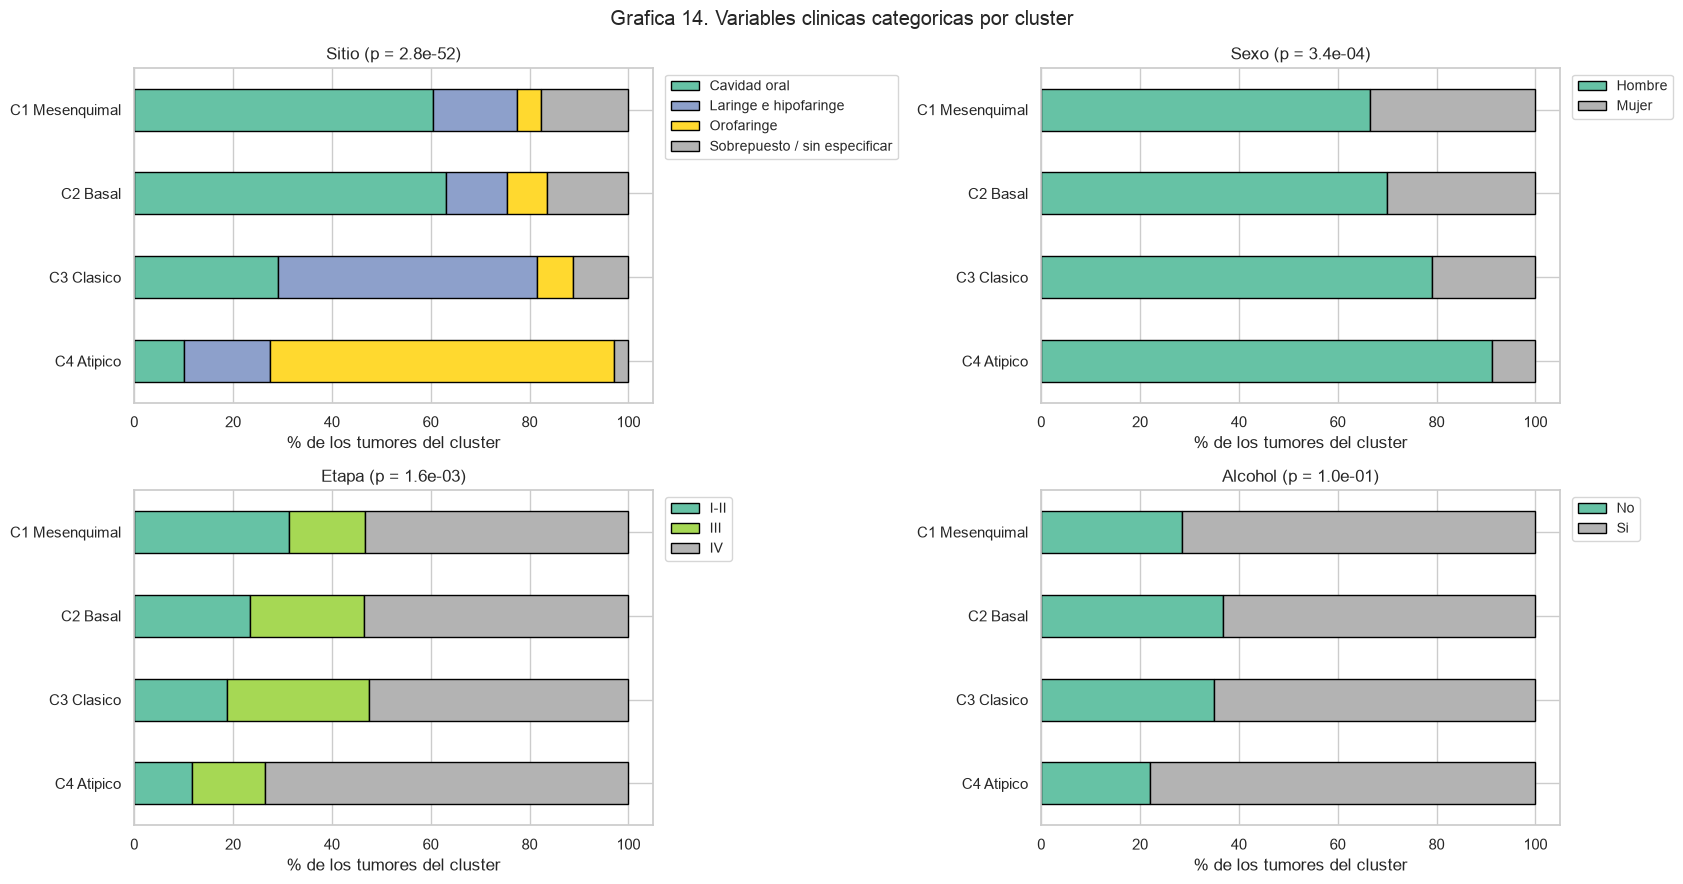

,Variable,Pacientes,Ji-cuadrada,gl,p-value,Esperados < 5
0,Sitio,520,266.8,9,2.8e-52,0
1,Sexo,520,18.5,3,3.4e-04,0
2,Etapa,506,21.3,6,1.6e-03,0
3,Alcohol,509,6.2,3,1.0e-01,0


In [ ]:
 
clin['Cluster'] = cluster_km.map(nombres)
orden_clusters = [nombres[c] for c in range(1, K + 1)]
categoricas = ['Sitio', 'Sexo', 'Etapa', 'Alcohol']

fig, axes = plt.subplots(2, 2, figsize=(17, 9))
pruebas = []
for ax, var in zip(axes.ravel(), categoricas):
    tabla = pd.crosstab(clin['Cluster'], clin[var]).reindex(orden_clusters)
    chi2, p, gl, esperados = stats.chi2_contingency(tabla)
    pruebas.append({'Variable': var, 'Pacientes': int(tabla.values.sum()), 'Ji-cuadrada': round(chi2, 1),
                    'gl': gl, 'p-value': f'{p:.1e}', 'Esperados < 5': int((esperados < 5).sum())})
    porcentaje = tabla.div(tabla.sum(axis=1), axis=0) * 100
    print(f"--- {var} (% de cada cluster)")
    print(porcentaje.round(1).to_string(), "\n")
    porcentaje.plot(kind='barh', stacked=True, ax=ax, colormap='Set2', edgecolor='black')
    ax.set_title(f'{var} (p = {p:.1e})')
    ax.set_xlabel('% de los tumores del cluster')
    ax.set_ylabel('')
    ax.invert_yaxis()
    ax.legend(bbox_to_anchor=(1.01, 1), loc='upper left', fontsize='small')
plt.suptitle('Grafica 14. Variables clinicas categoricas por cluster')
plt.tight_layout()
plt.show()
pd.DataFrame(pruebas)

**Sitio del tumor (p = 2.8 × 10⁻⁵²): la asociación más fuerte de todo el análisis.**

- **C4 Atípico es 69.6% orofaringe**, contra 5-8% en los demás clusters. **48 de los 78 tumores de orofaringe de la base caen en C4**, incluidos 34 de los 44 de amígdala y 13 de los 24 de base de lengua. Es justo el sitio donde se concentran los tumores por VPH.
- **C3 Clásico es 52.4% laringe e hipofaringe**, contra 12-17% en los demás. La laringe es el sitio más ligado al tabaco.
- **C1 Mesenquimal y C2 Basal son sobre todo de cavidad oral** (60.4% y 63.2%). C1 tiene 63 tumores de lengua, lo que explica su firma de **músculo esquelético**: una biopsia de lengua casi siempre incluye músculo.

**Sexo (p = 3.4 × 10⁻⁴):** C4 es **91.3% hombres**, contra 66-79% en los demás. Los tumores de orofaringe por VPH son mucho más frecuentes en hombres. Como antes del clustering se quitaron los genes que dependen del sexo (cromosoma Y y XIST), esta asociación no la provocan esos genes.

**Etapa clínica (p = 1.6 × 10⁻³):** C4 tiene la mayor proporción de etapa IV (73.5%, contra 52-54%). Parece contradictorio con un buen pronóstico, pero tiene explicación: los tumores por VPH suelen ser chicos pero se diseminan pronto a los ganglios del cuello, y en el sistema de etapas AJCC de 7.ª edición (el que usa TCGA) los ganglios grandes llevan directo a la etapa IV. Por eso la 8.ª edición creó una clasificación aparte para los tumores de orofaringe p16 positivos (Lydiatt et al., 2017).

**Alcohol (p = 0.10):** no hay asociación significativa. Entre 63% y 78% de los pacientes de todos los clusters reportan consumo de alcohol.

Ninguna tabla tiene frecuencias esperadas menores a 5, así que las pruebas ji-cuadrada son válidas.

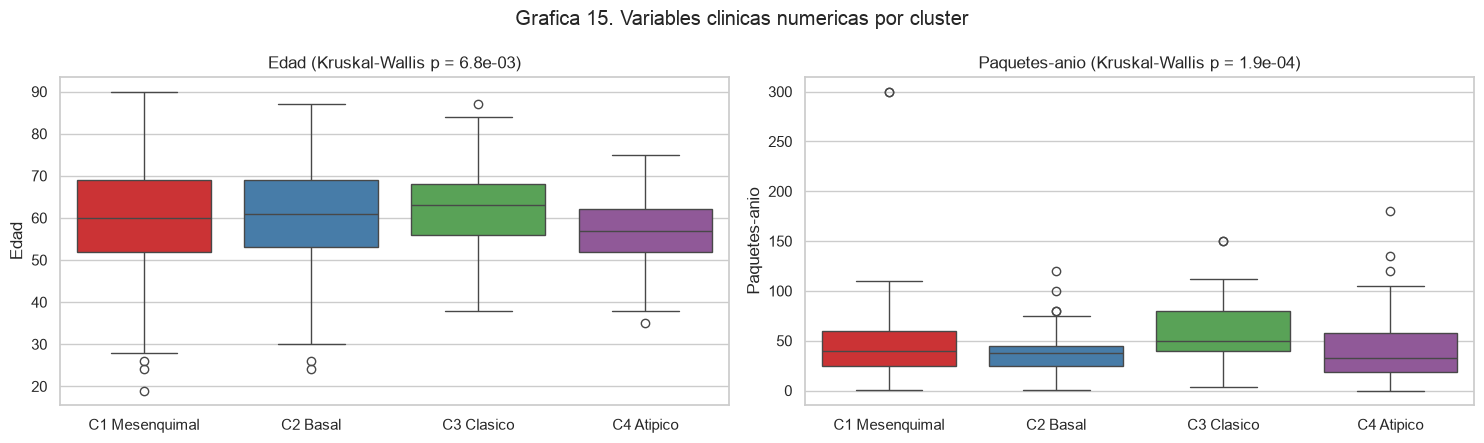

Edad       Paquetes-anio      
               median count        median count
Cluster                                        
C1 Mesenquimal   60.0   163          40.0    90
C2 Basal         61.0   163          38.0    89
C3 Clasico       63.0   124          50.0    81
C4 Atipico       57.0    69          33.0    36

In [ ]:
 
numericas = ['Edad', 'Paquetes-anio']
pal_nombres = {nombres[c]: colores[c] for c in range(1, K + 1)}

fig, axes = plt.subplots(1, 2, figsize=(15, 4.5))
for ax, var in zip(axes, numericas):
    grupos = [clin.loc[clin['Cluster'] == c, var].dropna() for c in orden_clusters]
    h, p = stats.kruskal(*grupos)
    sns.boxplot(data=clin, x='Cluster', y=var, hue='Cluster', order=orden_clusters, palette=pal_nombres, legend=False, ax=ax)
    ax.set_title(f'{var} (Kruskal-Wallis p = {p:.1e})')
    ax.set_xlabel('')
plt.suptitle('Grafica 15. Variables clinicas numericas por cluster')
plt.tight_layout()
plt.show()

clin.groupby('Cluster')[numericas].agg(['median', 'count']).reindex(orden_clusters).round(1)

- **Edad (Kruskal-Wallis p = 0.007):** C4 Atípico tiene los pacientes **más jóvenes** (mediana de 57 años, contra 60-63). Coincide con el perfil del cáncer por VPH, que aparece unos años antes que el causado por tabaco.
- **Paquetes-año (p = 0.0002):** C3 Clásico tiene **el mayor consumo de tabaco** (mediana de 50 paquetes-año, contra 33-40). C4 Atípico tiene el menor (33). Es la relacion esperada: el subtipo con la firma de detoxificación de tóxicos y de estrés oxidativo es el de los fumadores más intensos. La activación de esos genes es la respuesta de las células al humo del tabaco. Esta variable solo está para 296 pacientes, pero la diferencia es muy significativa.

Por último, la supervivencia global con curvas de Kaplan-Meier.

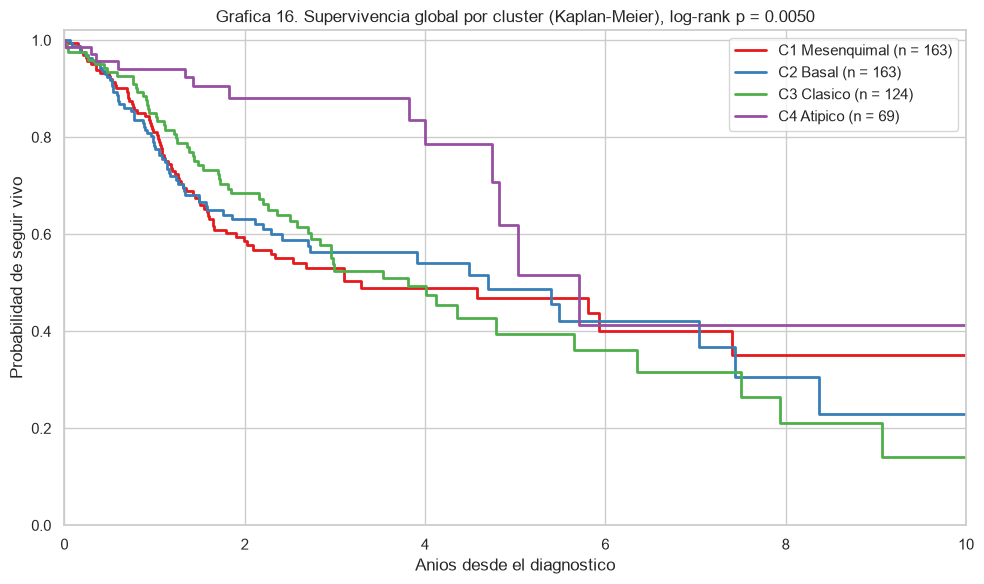

Log-rank global (4 clusters): ji-cuadrada = 12.85, p = 0.0050
Log-rank C4 Atipico contra el resto: p = 0.00034


,Cluster,Pacientes,Fallecidos,Supervivencia a 3 anios,Supervivencia a 5 anios
0,C1 Mesenquimal,163,78,0.529,0.468
1,C2 Basal,163,70,0.563,0.488
2,C3 Clasico,124,60,0.525,0.395
3,C4 Atipico,69,13,0.881,0.618


In [ ]:
 
def logrank_global(tiempos, eventos, grupos):
    """Prueba log-rank para comparar 2 o mas curvas de supervivencia (ji-cuadrada con k-1 gl)."""
    g_unicos = np.unique(grupos)
    O, E = np.zeros(len(g_unicos)), np.zeros(len(g_unicos))
    V = np.zeros((len(g_unicos), len(g_unicos)))
    for t in np.unique(tiempos[eventos == 1]):
        en_riesgo = tiempos >= t
        mueren = (tiempos == t) & (eventos == 1)
        n, d = en_riesgo.sum(), mueren.sum()
        n_g = np.array([(en_riesgo & (grupos == g)).sum() for g in g_unicos])
        O += np.array([(mueren & (grupos == g)).sum() for g in g_unicos])
        E += d * n_g / n
        if n > 1:
            V += d * (n - d) / (n - 1) * (np.diag(n_g / n) - np.outer(n_g, n_g) / n**2)
    dif = (O - E)[:-1]
    chi2 = dif @ np.linalg.solve(V[:-1, :-1], dif)
    return chi2, stats.chi2.sf(chi2, len(g_unicos) - 1)

def datos_censurados(d):
    return stats.CensoredData(uncensored=d.loc[d['Fallecio'] == 1, 'Tiempo (anios)'].values,
                              right=d.loc[d['Fallecio'] == 0, 'Tiempo (anios)'].values)

surv = clin.dropna(subset=['Tiempo (anios)', 'Fallecio'])
fig, ax = plt.subplots(figsize=(10, 6))
filas = []
for c in range(1, K + 1):
    d = surv[surv['Cluster'] == nombres[c]]
    km_c = stats.ecdf(datos_censurados(d)).sf
    ax.step(np.concatenate([[0], km_c.quantiles]), np.concatenate([[1], km_c.probabilities]),
            where='post', color=colores[c], linewidth=2, label=f'{nombres[c]} (n = {len(d)})')
    filas.append({'Cluster': nombres[c], 'Pacientes': len(d), 'Fallecidos': int(d['Fallecio'].sum()),
                  'Supervivencia a 3 anios': round(float(km_c.evaluate(3)), 3),
                  'Supervivencia a 5 anios': round(float(km_c.evaluate(5)), 3)})
chi2, p_global = logrank_global(surv['Tiempo (anios)'].values, surv['Fallecio'].values.astype(int), surv['Cluster'].values)
ax.set_xlim(0, 10)
ax.set_ylim(0, 1.02)
ax.set_xlabel('Anios desde el diagnostico')
ax.set_ylabel('Probabilidad de seguir vivo')
ax.set_title(f'Grafica 16. Supervivencia global por cluster (Kaplan-Meier), log-rank p = {p_global:.4f}')
ax.legend()
plt.tight_layout()
plt.show()

c_atipico = [c for c in range(1, K + 1) if 'Atipico' in nombres[c]][0]
es_atipico = surv['Cluster'] == nombres[c_atipico]
p_atipico = stats.logrank(datos_censurados(surv[es_atipico]), datos_censurados(surv[~es_atipico])).pvalue
print(f"Log-rank global (4 clusters): ji-cuadrada = {chi2:.2f}, p = {p_global:.4f}")
print(f"Log-rank {nombres[c_atipico]} contra el resto: p = {p_atipico:.5f}")
pd.DataFrame(filas)

- **Las 4 curvas no son iguales** (log-rank global p = 0.005). La diferencia viene de **C4 Atípico**: comparado con el resto de los tumores, su supervivencia es significativamente mejor (**p = 0.0003**).
- **C4 Atípico:** a 3 años sigue vivo el **88%** de los pacientes, contra 53-56% en los demás clusters. A 5 años, 62% contra 40-49%. Solo falleció el 19% (13 de 69), contra 43-48% en los demás.
- **C1, C2 y C3** tienen curvas casi encimadas durante los primeros 5 años. Entre ellos, C3 Clásico (el de los fumadores) es el que tiene la supervivencia más baja a 5 años (40%).
- La caída de la curva de C4 entre los 4 y 6 años se basa en pocos pacientes: la mediana del tiempo observado en toda la base es de 1.8 años, y en ese tramo quedan muy pocos pacientes de C4 en observación. Lo sólido es la diferencia de los primeros 4 años.

### Resumen de los clusters

Vamos a juntar en una sola tabla lo más importante de cada cluster, tanto de genes como de las variables clínicas.

Tabla 3. Perfil de cada cluster

| | C1 Mesenquimal | C2 Basal | C3 Clásico | C4 Atípico |
|---|---|---|---|---|
| Tumores | 164 | 163 | 124 | 69 |
| Genes que lo definen | Músculo, estroma, matriz extracelular | Queratinización, KRT14; pocas células inmunes | Xenobióticos y estrés oxidativo (AKR1C, GPX2), SOX2 | p16 (CDKN2A), SYCP2, linfocitos B; sin queratinización |
| Sitio principal | Cavidad oral (60%), lengua | Cavidad oral (63%) | **Laringe (52%)** | **Orofaringe (70%)** |
| Hombres | 67% | 70% | 79% | **91%** |
| Edad (mediana) | 60 | 61 | 63 | **57** |
| Paquetes-año (mediana) | 40 | 38 | **50** | 33 |
| Supervivencia a 5 años | 47% | 49% | 40% | **62%** |

C4 Atípico y C3 Clásico tienen un perfil clínico propio: C4 es el cáncer de orofaringe asociado al VPH y C3 el cáncer de laringe del fumador. C1 Mesenquimal y C2 Basal son clínicamente parecidos (los dos son sobre todo de cavidad oral, con edad, sexo y supervivencia similares); los separa la composición del tumor (estroma contra epitelio queratinizado), no el perfil del paciente.

# Discusión

Vamos a comparar los resultados con un artículo que usa los mismos datos de TCGA, para ver si los clusters que encontramos coinciden con lo que ya se sabe de este cáncer.

### Artículo revisado

**The Cancer Genome Atlas Network (2015). *Comprehensive genomic characterization of head and neck squamous cell carcinomas*. Nature, 517, 576-582.**

Es el artículo principal de TCGA sobre este cáncer y usa la misma cohorte de este reporte. Analiza los primeros 279 tumores de TCGA-HNSC con varias plataformas a la vez: mutaciones, número de copias, metilación, expresión de ARN y de proteínas. En la parte de expresión, clasifica los tumores en los **cuatro subtipos descritos antes por Walter et al. (2013)**: **atípico, basal, clásico y mesenquimal**. Sus hallazgos principales para cada subtipo:

- Los tumores **VPH positivos** (cerca del 13% de su cohorte) se concentran en el subtipo **atípico** y tienen un perfil genómico distinto al de los tumores por tabaco.
- El subtipo **clásico** se asocia con **tabaquismo intenso**, con tumores de **laringe** y con alteraciones en genes de la respuesta al **estrés oxidativo** (NFE2L2, KEAP1, CUL3).
- El **mesenquimal** se caracteriza por genes de transición epitelio-mesénquima y de células inmunes, y el **basal** por genes de la capa basal del epitelio, como KRT14, y por el ligando de EGFR TGFA.

### Similitudes

Estos son los puntos en los que el reporte llega a lo mismo que el artículo:

- **Los mismos 4 subtipos.** Con solo expresión génica, K-means y una silueta para elegir $K$, se llegó a 4 grupos que coinciden con los 4 subtipos del artículo, cada uno con su firma de referencia como la más alta.
- **El grupo atípico es el grupo con perfil de VPH.** C4 junta los tumores de orofaringe, con p16 (CDKN2A) alto, pacientes más jóvenes, casi todos hombres y con menos tabaco. Incluso su tamaño es paracido: C4 es el 13.3% de los tumores, la misma proporción de tumores VPH positivos que reporta el artículo.
- **El grupo clásico es el del fumador.** C3 concentra la laringe, el mayor consumo de tabaco y la sobreexpresión de genes de la vía NRF2 (AKR1C1, AKR1C3, GPX2, NQO1), que es justo la vía que el artículo encuentra alterada en este subtipo por mutaciones en NFE2L2 y KEAP1.
- **Mejor supervivencia del grupo de VPH.** Coincide con lo reportado en la literatura clínica: los tumores de orofaringe VPH positivos tienen mucho mejor supervivencia (Ang et al., 2010).

### Diferencias

Y estos son los puntos en los que se separan, ya sea por el método o por los resultados:

- **Metodología:** el artículo usa 279 tumores y varias plataformas, mide el VPH directamente (detectando transcritos virales en el RNA-seq) y asigna los subtipos con la clasificación de Walter et al. Aquí se usaron los **520 tumores** de la cohorte completa, con los datos reprocesados por el GDC (STAR-TPM), **solo expresión génica**, y los subtipos salieron sin ninguna referencia previa: los nombres se pusieron después de formar los grupos.
- **El VPH aquí es indirecto.** El fenotipo de Xena no trae el estado de VPH, así que la conexión de C4 con el VPH se apoya en evidencia indirecta (sitio, p16, genes de ciclo celular, sexo, edad y supervivencia). Es una evidencia consistente, pero no una medición.
- **El grupo mesenquimal está inflado por músculo.** Una parte importante de la firma de C1 son genes de músculo esquelético, que vienen del tejido de la lengua incluido en la muestra y no de las células tumorales. En los datos de este reporte, el "subtipo mesenquimal" mezcla biología del tumor (estroma, fibroblastos, invasión) con composición de la muestra.
- **El grupo basal se define más por queratinización.** En el artículo el basal se describe por KRT14 y TGFA; en C2 lo que más destaca es la diferenciación terminal (KRT1, SPRR, LCE3), aunque también tiene el KRT14 más alto.

# Conclusión y reflexión final

Para cerrar, vamos a resumir qué se aprendió de los datos, qué limitaciones tiene el análisis y qué se podría hacer después.

Aprendizajs
- **Los tumores no se separan en grupos totalmente aparte.** Se parecen más a una mezcla continua con 4 zonas. La silueta salió baja (0.181), o sea que los grupos se tocan en las orillas, pero casi no cambian al correr K-means con otras semillas y cada uno tiene cientos de genes que lo distinguen. Los grupos sí existen, solo que sus fronteras no son claras.
- **Mucho de lo que separa a un tumor de otro es lo que viene junto con él en la muestra.** Cuando se toma un pedazo de tumor también se lleva tejido de alrededor, como músculo y células de defensa del cuerpo. Los primeros componentes del PCA separan justo eso: qué tanto de la muestra es tumor y qué tanto es tejido de alrededor.
- **El clustering encontró grupos que tienen sentido médico.** Sin ver ningún dato de los pacientes, separó dos tipos de cáncer muy conocidos: el que causa el virus del papiloma humano (VPH) en la garganta (C4: 70% son de amígdala o base de la lengua, 91% hombres, más jóvenes, y 62% siguen vivos a 5 años contra 40-49% en los demás grupos) y el cáncer de laringe de los fumadores (C3: 52% son de laringe y son los que más fumaron). Son los dos grandes origenes de esta enfermedad, y salieron solo de los genes.

Lo importante para el problema real: **lo que se llama "cáncer de cabeza y cuello" en realidad son al menos dos enfermedades distintas**, con causas y pronósticos diferentes. A los pacientes del grupo del VPH les va mucho mejor con el mismo tratamiento. avanzado está el cáncer ya los clasifica aparte.

Limitaciones
- **No sabemos qué pacientes tienen VPH.** Los datos no lo traen, así que la relación de C4 con el virus se deduce por otras pistas: el sitio del tumor, un gen que sube cuando hay VPH, la edad y la supervivencia. Todas apuntan a lo mismo, pero no es una medición directa.
- **Las muestras no son tumor puro.** Una parte del grupo C1 se formó por el músculo de la lengua que venía en la muestra, y una parte de C4 por las células de defensa de la amígdala. Algunos grupos dicen tanto de cómo se tomó la muestra como del tumor mismo.
- **Faltan datos de los pacientes.** 43% no tiene el dato de cuánto fumó, no hay información del tratamiento que recibió cada uno, y la mitad de los pacientes tiene menos de 2 años de seguimiento, así que la parte final de las curvas de supervivencia se basa en muy pocas personas.
- **La comparación de supervivencia no toma en cuenta otras diferencias.** Los pacientes de C4 son más jóvenes y tienen el tumor en otro sitio, y la prueba que se usó no separa el efecto del grupo del efecto de la edad o del sitio.
- **Cada tumor tiene una sola muestra,** tomada una sola vez y de un solo pedazo del tumor.

Trabajo futuro
- **Corregir por el tejido de alrededor que viene en cada muestra**, ya sea estimando qué porcentaje de cada muestra es tumor o quitando los genes del músculo, y repetir el clustering para ver qué parte de C1 se mantiene.
- **Conseguir el dato de VPH de cada paciente**, que TCGA publicó junto con su artículo, para confirmar directamente que C4 es el grupo del virus.
- **Comparar la supervivencia tomando en cuenta la edad, la etapa y el sitio al mismo tiempo** (por ejemplo con un modelo de Cox), para saber si pertenecer a un grupo cambia el pronóstico por sí solo.
- **Probar los grupos con pacientes de otro estudio**, para ver si se repiten fuera de TCGA.
- **Repetir el clustering muchas veces con partes de los datos** y ver qué tumores cambian de grupo, para saber qué tan seguro es el grupo de cada tumor.

# Referencias

- Cancer Genome Atlas Network (2015). Comprehensive genomic characterization of head and neck squamous cell carcinomas. *Nature*, 517(7536), 576-582. https://doi.org/10.1038/nature14129
- Walter, V., Yin, X., Wilkerson, M. D., et al. (2013). Molecular subtypes in head and neck cancer exhibit distinct patterns of chromosomal gain and loss of canonical cancer genes. *PLoS ONE*, 8(2), e56823. https://doi.org/10.1371/journal.pone.0056823
- Ang, K. K., Harris, J., Wheeler, R., et al. (2010). Human papillomavirus and survival of patients with oropharyngeal cancer. *New England Journal of Medicine*, 363(1), 24-35. https://doi.org/10.1056/NEJMoa0912217
- Lydiatt, W. M., Patel, S. G., O'Sullivan, B., et al. (2017). Head and neck cancers - major changes in the American Joint Committee on Cancer eighth edition cancer staging manual. *CA: A Cancer Journal for Clinicians*, 67(2), 122-137. https://doi.org/10.3322/caac.21389
- Goldman, M. J., Craft, B., Hastie, M., et al. (2020). Visualizing and interpreting cancer genomics data via the Xena platform. *Nature Biotechnology*, 38(6), 675-678. https://doi.org/10.1038/s41587-020-0546-8
- UCSC Xena. *GDC TCGA Head and Neck Cancer (HNSC)*. https://xenabrowser.net/datapages/?cohort=GDC%20TCGA%20Head%20and%20Neck%20Cancer%20(HNSC)
- Benjamini, Y., & Hochberg, Y. (1995). Controlling the false discovery rate: a practical and powerful approach to multiple testing. *Journal of the Royal Statistical Society: Series B*, 57(1), 289-300.
- James, G., Witten, D., Hastie, T., Tibshirani, R., & Taylor, J. (2023). *An Introduction to Statistical Learning with Applications in Python*. Springer. Capítulo 12: Unsupervised Learning.
- Pedregosa, F. et al. (2011). Scikit-learn: Machine Learning in Python. *Journal of Machine Learning Research*, 12, 2825-2830.